# RetinaNet: training, validation and submission

We retain all existing training configurations and checkpoint identities. In the default mode we load completed experiments, compare the three fold models and their ensembles on the official validation sequences, and export test predictions with the selected settings. We do not retrain models when finalizing results.

**How we run this notebook.** We use the original Colab GPU environment and Drive folder. We run the setup/definition cells, then continue from **Finalization: audit and validation-based selection**. On a fresh runtime we can use Run all: `RUN_TRAINING_QUEUE=False` skips the training queue. `RUN_SMOKE_TESTS=False` skips the already completed model smoke tests. All inference chunks and class metrics are saved to Drive. Completed chunks/classes are reused; an unfinished chunk or class is repeated after interruption. The final CSV is `ucu_ai_hw2/retinanet_final/submission_retinanet_selected.csv`.

We keep model experiments and final inference changes separate. We compare the original five-epoch anchor/focal-loss experiments using their fixed fold protocol. We then tune a small inference grid on `val/`, whose sequences were excluded from every training fold. Once used for inference selection, this split is a tuning validation set, not an untouched test estimate. We never tune using test labels or leaderboard feedback.

Only the supplied notebook and rules are available here; the actual model weights and images remain on our Drive/Colab. The final metrics and CSV are generated there, rather than fabricated in this document.

In [ ]:
RUN_SMOKE_TESTS = False
RUN_TRAINING_QUEUE = False

# RetinaNet: One-Stage Anchor-Based Detection

We investigate RetinaNet as a one-stage alternative to Faster R-CNN.
RetinaNet predicts object classes and bounding boxes directly from
multi-scale feature maps, without a separate region proposal stage.

We use the same sequence-based folds and evaluation protocol as our
two-stage experiments. We investigate anchor sizes for small objects
and focal-loss parameters, and support checkpoint-based training recovery.

In [ ]:
%pip install -q -U kaggle

In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggle_token").strip()

print("Kaggle token loaded from Colab Secrets.")

Kaggle token loaded from Colab Secrets.


In [ ]:
!kaggle competitions download \
    -c multiple-object-video-detection-hw-2-ucu-ai-2026 \
    -f test_images.csv \
    -p /content/detection_data

100% 265k/265k [00:00<00:00, 1.22MB/s]



In [ ]:
!kaggle competitions download \
    -c multiple-object-video-detection-hw-2-ucu-ai-2026 \
    -p /content/detection_data

100% 9.88G/9.88G [01:59<00:00, 88.8MB/s]



In [ ]:
from pathlib import Path
import zipfile

DATA_ROOT = Path("/content/detection_data")

archives = sorted(DATA_ROOT.glob("*.zip"))
assert archives, "Downloaded archive not found."

for archive in archives:
    print("Extracting:", archive.name)
    with zipfile.ZipFile(archive) as zipped:
        zipped.extractall(DATA_ROOT)

assert (DATA_ROOT / "train/annotations_coco.json").is_file()
assert (DATA_ROOT / "val/annotations_coco.json").is_file()
assert (DATA_ROOT / "test_images.csv").is_file()

print("Dataset paths verified.")

Extracting: multiple-object-video-detection-hw-2-ucu-ai-2026.zip
Dataset paths verified.


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/ucu_ai_hw2")
RUNS_DIR = PROJECT_DIR / "retinanet_runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

print("Persistent runs directory:", RUNS_DIR)

Mounted at /content/drive
Persistent runs directory: /content/drive/MyDrive/ucu_ai_hw2/retinanet_runs


### Reproducible sequence-based splits

We reuse the fold assignments from our Faster R-CNN experiments.
Each video belongs to exactly one fold, preventing leakage between
correlated frames from the same sequence.

We keep images on the Colab runtime disk for loading and save training
checkpoints and experiment results to Google Drive.

In [ ]:
import json
import random
import platform

import numpy as np
import pandas as pd
import torch
import torchvision

from torchvision.ops import nms
from tqdm.auto import tqdm


SEED = 42
N_FOLDS = 3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

assert torch.cuda.is_available(), "Enable the GPU runtime."
DEVICE = torch.device("cuda:0")

FOLDS_PATH = PROJECT_DIR / "train_folds.csv"
assert FOLDS_PATH.is_file(), f"Missing: {FOLDS_PATH}"

with (DATA_ROOT / "train/annotations_coco.json").open() as file:
    train_coco = json.load(file)

frames = pd.DataFrame(train_coco["images"]).rename(
    columns={"id": "image_id"}
)

saved_folds = pd.read_csv(FOLDS_PATH)

required_columns = {"image_id", "fold"}
assert required_columns.issubset(saved_folds.columns)
assert saved_folds["image_id"].is_unique
assert frames["image_id"].is_unique

assert set(saved_folds["image_id"]) == set(frames["image_id"])
assert set(saved_folds["fold"]) == set(range(N_FOLDS))

comparison = frames.merge(
    saved_folds,
    on="image_id",
    suffixes=("_data", "_saved"),
    validate="one_to_one",
)

for column in ("video", "frame_id", "file_name"):
    if column in saved_folds.columns:
        assert comparison[f"{column}_data"].eq(
            comparison[f"{column}_saved"]
        ).all(), f"Manifest mismatch: {column}"

train_frames = frames.merge(
    saved_folds[["image_id", "fold"]],
    on="image_id",
    validate="one_to_one",
).sort_values(
    ["video", "frame_id", "image_id"]
).reset_index(drop=True)

assert train_frames.groupby("video")["fold"].nunique().eq(1).all()

test_boxes = torch.tensor(
    [[0, 0, 10, 10], [1, 1, 9, 9]],
    dtype=torch.float32,
    device=DEVICE,
)
test_scores = torch.tensor([0.9, 0.8], device=DEVICE)

assert nms(test_boxes, test_scores, 0.5).tolist() == [0]

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(DEVICE))
print("Dataset:", DATA_ROOT)
print("Checkpoints:", RUNS_DIR)

display(
    train_frames.groupby("fold").agg(
        clips=("video", "nunique"),
        frames=("image_id", "size"),
    )
)

del test_boxes, test_scores

print("GPU and shared fold checks passed.")

Python: 3.13.16
PyTorch: 2.11.0+cu130
TorchVision: 0.26.0+cu130
GPU: Tesla T4
Dataset: /content/detection_data
Checkpoints: /content/drive/MyDrive/ucu_ai_hw2/retinanet_runs


,clips,frames
fold,,
0,19,8080
1,19,8082
2,18,8039


GPU and shared fold checks passed.


### Images, targets, and ignored regions

We load RGB images as floating-point tensors in the range [0, 1].
The model will apply resizing and normalization internally.

We convert COCO boxes from pixel-based xywh to xyxy coordinates.
For RetinaNet, we map the eight target categories to labels 0–7.

We keep ignored regions separate from target objects. During training,
we will exclude background anchors substantially covered by these
regions while preserving positive matches.

In [ ]:
from collections import defaultdict

from PIL import Image
from torch.utils.data import Dataset
from torchvision.transforms.functional import pil_to_tensor


targets_by_image = defaultdict(list)
ignored_by_image = defaultdict(list)

known_image_ids = set(train_frames["image_id"])
category_ids = {category["id"] for category in train_coco["categories"]}

assert category_ids == set(range(1, 9))

for annotation in train_coco["annotations"]:
    image_id = annotation["image_id"]
    assert image_id in known_image_ids

    is_ignored = (
        bool(annotation.get("iscrowd", 0))
        or bool(annotation.get("ignore", 0))
    )

    if is_ignored:
        ignored_by_image[image_id].append(annotation)
    else:
        assert annotation["category_id"] in category_ids
        targets_by_image[image_id].append(annotation)


def coco_to_xyxy(annotations):
    boxes = torch.tensor(
        [annotation["bbox"] for annotation in annotations],
        dtype=torch.float32,
    ).reshape(-1, 4)

    boxes[:, 2:] += boxes[:, :2]
    return boxes


class RetinaNetDataset(Dataset):
    def __init__(self, frame_table):
        self.frames = frame_table.reset_index(drop=True).copy()

    def __len__(self):
        return len(self.frames)

    def __getitem__(self, index):
        row = self.frames.iloc[index]
        image_id = int(row["image_id"])

        image_path = DATA_ROOT / "train" / row["file_name"]

        with Image.open(image_path) as source:
            image = source.convert("RGB")

            if image.size != (int(row["width"]), int(row["height"])):
                raise ValueError(f"Image size mismatch: {image_path}")

            image = pil_to_tensor(image).float().div_(255)

        annotations = targets_by_image[image_id]
        boxes = coco_to_xyxy(annotations)

        target = {
            "boxes": boxes,
            "labels": torch.tensor(
                [
                    annotation["category_id"] - 1
                    for annotation in annotations
                ],
                dtype=torch.int64,
            ),
            "image_id": torch.tensor(image_id, dtype=torch.int64),
            "area": (
                (boxes[:, 2] - boxes[:, 0])
                * (boxes[:, 3] - boxes[:, 1])
            ),
            "iscrowd": torch.zeros(
                len(annotations),
                dtype=torch.int64,
            ),
            "ignore_boxes": coco_to_xyxy(
                ignored_by_image[image_id]
            ),
        }

        return image, target


def detection_collate(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)


ACTIVE_FOLD = 0

fit_frames = train_frames.loc[
    train_frames["fold"].ne(ACTIVE_FOLD)
].copy()

holdout_frames = train_frames.loc[
    train_frames["fold"].eq(ACTIVE_FOLD)
].copy()

assert set(fit_frames["video"]).isdisjoint(
    holdout_frames["video"]
)

fit_dataset = RetinaNetDataset(fit_frames)
holdout_dataset = RetinaNetDataset(holdout_frames)

for index in range(2):
    image, target = fit_dataset[index]

    assert target["boxes"].shape == (len(target["labels"]), 4)
    assert target["ignore_boxes"].ndim == 2
    assert ((target["labels"] >= 0) & (target["labels"] < 8)).all()

    print(
        f"Sample {index}: image={tuple(image.shape)}, "
        f"targets={len(target['labels'])}, "
        f"ignored={len(target['ignore_boxes'])}"
    )

print("Training frames:", len(fit_dataset))
print("Fold validation frames:", len(holdout_dataset))
print("RetinaNet dataset checks passed.")

del image, target

Sample 0: image=(3, 756, 1344), targets=23, ignored=32
Sample 1: image=(3, 756, 1344), targets=23, ignored=32
Training frames: 16121
Fold validation frames: 8080
RetinaNet dataset checks passed.


### Ignore-aware anchor matching

We measure intersection over anchor area (IoA) between anchors and
ignored regions. Background anchors with IoA of at least 0.5 are excluded
from the loss.

We preserve positive matches, including objects overlapping ignored
regions. We compute overlaps in vectorized chunks to limit memory use.

In [ ]:
from torchvision.models.detection import _utils as detection_utils
from torchvision.models.detection.transform import (
    GeneralizedRCNNTransform,
    resize_boxes,
)


def max_ignore_ioa(boxes, ignore_boxes, chunk_size=4096):
    boxes = boxes.float()
    ignore_boxes = ignore_boxes.to(
        device=boxes.device,
        dtype=torch.float32,
    )

    result = boxes.new_zeros(len(boxes))

    if len(boxes) == 0 or len(ignore_boxes) == 0:
        return result

    for start in range(0, len(boxes), chunk_size):
        chunk = boxes[start:start + chunk_size]

        top_left = torch.maximum(
            chunk[:, None, :2],
            ignore_boxes[None, :, :2],
        )
        bottom_right = torch.minimum(
            chunk[:, None, 2:],
            ignore_boxes[None, :, 2:],
        )

        intersection = (
            (bottom_right - top_left)
            .clamp_min(0)
            .prod(dim=-1)
        )

        anchor_area = (
            (chunk[:, 2:] - chunk[:, :2])
            .clamp_min(0)
            .prod(dim=-1)
            .clamp_min(1e-6)
        )

        result[start:start + len(chunk)] = (
            intersection / anchor_area[:, None]
        ).amax(dim=1)

    return result


def exclude_ignored_anchors(
    matched_indices,
    anchors,
    ignore_boxes,
    threshold=0.5,
):
    updated = matched_indices.clone()

    background = (
        matched_indices == detection_utils.Matcher.BELOW_LOW_THRESHOLD
    )

    background_indices = torch.where(background)[0]

    if background_indices.numel() > 0:
        overlaps = max_ignore_ioa(
            anchors[background_indices],
            ignore_boxes,
        )

        excluded_indices = background_indices[overlaps >= threshold]

        updated[excluded_indices] = (
            detection_utils.Matcher.BETWEEN_THRESHOLDS
        )

    return updated


class IgnoreAwareTransform(GeneralizedRCNNTransform):
    def resize(self, image, target=None):
        original_size = image.shape[-2:]

        if target is not None:
            target = target.copy()
            ignore_boxes = target.get("ignore_boxes")
        else:
            ignore_boxes = None

        image, target = super().resize(image, target)

        if ignore_boxes is not None:
            target["ignore_boxes"] = resize_boxes(
                ignore_boxes,
                original_size,
                image.shape[-2:],
            )

        return image, target

In [ ]:
if RUN_SMOKE_TESTS:
    anchors = torch.tensor(
        [
            [0, 0, 10, 10],      # Background, fully ignored.
            [0, 0, 20, 10],      # Positive, must be preserved.
            [20, 20, 30, 30],    # Background, outside ignored region.
            [0, 0, 10, 10],      # Already ignored by the matcher.
        ],
        dtype=torch.float32,
    )

    ignore_boxes = torch.tensor(
        [[0, 0, 10, 10]],
        dtype=torch.float32,
    )

    matched_indices = torch.tensor([-1, 0, -1, -2])

    updated = exclude_ignored_anchors(
        matched_indices,
        anchors,
        ignore_boxes,
    )

    assert updated.tolist() == [-2, 0, -1, -2]

    empty_result = exclude_ignored_anchors(
        matched_indices,
        anchors,
        torch.empty((0, 4)),
    )
    assert torch.equal(empty_result, matched_indices)

    print("IoA:", max_ignore_ioa(anchors, ignore_boxes).tolist())
    print("Updated matches:", updated.tolist())
    print("Positive preservation and empty-region checks passed.")


### Configurable focal loss

We use focal loss to reduce the contribution of easy classification
examples. The parameter gamma controls this down-weighting, while alpha
balances positive and negative classification terms.

We start with alpha = 0.25 and gamma = 2.0. We preserve TorchVision's
per-image normalization by the number of positive anchors and exclude
ignored anchors from classification loss.

We retain the GIoU regression loss used by RetinaNet ResNet50 FPN v2.

In [ ]:
from torchvision.ops import box_iou, sigmoid_focal_loss
from torchvision.models.detection.retinanet import (
    RetinaNet,
    RetinaNetClassificationHead,
)


class ConfigurableClassificationHead(RetinaNetClassificationHead):
    focal_alpha = 0.25
    focal_gamma = 2.0

    def compute_loss(self, targets, head_outputs, matched_idxs):
        image_losses = []

        for target, logits, matches in zip(
            targets,
            head_outputs["cls_logits"],
            matched_idxs,
        ):
            logits = logits.float()

            positive = matches >= 0
            valid = matches != self.BETWEEN_THRESHOLDS

            class_targets = torch.zeros_like(logits)

            class_targets[
                positive,
                target["labels"][matches[positive]],
            ] = 1.0

            loss = sigmoid_focal_loss(
                logits[valid],
                class_targets[valid],
                alpha=self.focal_alpha,
                gamma=self.focal_gamma,
                reduction="sum",
            )

            normalizer = positive.sum().clamp_min(1).to(logits.dtype)
            image_losses.append(loss / normalizer)

        return torch.stack(image_losses).mean()


class IgnoreAwareRetinaNet(RetinaNet):
    ignore_ioa_threshold = 0.5

    def compute_loss(self, targets, head_outputs, anchors):
        matched_indices = []

        for target, anchors_per_image in zip(targets, anchors):
            if target["boxes"].numel() == 0:
                matches = torch.full(
                    (len(anchors_per_image),),
                    detection_utils.Matcher.BELOW_LOW_THRESHOLD,
                    dtype=torch.int64,
                    device=anchors_per_image.device,
                )
            else:
                quality = box_iou(
                    target["boxes"].float(),
                    anchors_per_image.float(),
                )
                matches = self.proposal_matcher(quality)

            matches = exclude_ignored_anchors(
                matches,
                anchors_per_image,
                target["ignore_boxes"],
                threshold=self.ignore_ioa_threshold,
            )
            matched_indices.append(matches)

        return self.head.compute_loss(
            targets,
            head_outputs,
            anchors,
            matched_indices,
        )

In [ ]:
if RUN_SMOKE_TESTS:
    reference_head = RetinaNetClassificationHead(
        in_channels=32,
        num_anchors=1,
        num_classes=8,
    )

    custom_head = ConfigurableClassificationHead(
        in_channels=32,
        num_anchors=1,
        num_classes=8,
    )

    test_logits = torch.zeros(
        (1, 4, 8),
        requires_grad=True,
    )

    test_targets = [{"labels": torch.tensor([0, 7])}]
    test_matches = [torch.tensor([0, 1, -1, -2])]
    test_outputs = {"cls_logits": test_logits}

    reference_loss = reference_head.compute_loss(
        test_targets,
        test_outputs,
        test_matches,
    )

    custom_loss = custom_head.compute_loss(
        test_targets,
        test_outputs,
        test_matches,
    )

    torch.testing.assert_close(custom_loss, reference_loss)

    custom_loss.backward()

    assert torch.isfinite(test_logits.grad).all()
    assert test_logits.grad[0, :3].abs().sum() > 0
    assert test_logits.grad[0, 3].abs().sum() == 0

    ignored_logits = torch.zeros((1, 2, 8), requires_grad=True)

    ignored_loss = custom_head.compute_loss(
        [{"labels": torch.empty(0, dtype=torch.int64)}],
        {"cls_logits": ignored_logits},
        [torch.tensor([-2, -2])],
    )

    assert ignored_loss.item() == 0.0
    ignored_loss.backward()
    assert ignored_logits.grad.abs().sum() == 0

    print(f"Reference focal loss: {reference_loss.item():.6f}")
    print(f"Custom focal loss: {custom_loss.item():.6f}")
    print("Loss equivalence and ignored-gradient checks passed.")

    del (
        reference_head,
        custom_head,
        test_logits,
        test_targets,
        test_matches,
        test_outputs,
        reference_loss,
        custom_loss,
        ignored_logits,
        ignored_loss,
    )


### Pretrained RetinaNet baseline

We initialize RetinaNet ResNet50 FPN v2 from COCO-pretrained weights.
We replace only the final classification layer to predict our eight
classes and retain the pretrained feature extraction and regression layers.

We start with the standard anchor configuration and the same input-size
limits as our Faster R-CNN baseline. Our later anchor experiment will
change anchor sizes while preserving the number of anchors per location.

In [ ]:
import math

from torch import nn
from torchvision.models.detection import (
    retinanet_resnet50_fpn_v2,
    RetinaNet_ResNet50_FPN_V2_Weights,
)
from torchvision.models.detection.anchor_utils import AnchorGenerator


BASE_MODEL_CONFIG = {
    "model": "retinanet_resnet50_fpn_v2",
    "num_classes": 8,
    "min_size": 640,
    "max_size": 1152,
    "anchor_base_sizes": [32, 64, 128, 256, 512],
    "aspect_ratios": [0.5, 1.0, 2.0],
    "focal_alpha": 0.25,
    "focal_gamma": 2.0,
    "ignore_ioa_threshold": 0.5,
    "score_thresh": 0.001,
    "nms_thresh": 0.5,
    "detections_per_img": 500,
    "topk_candidates": 1000,
}


def build_retinanet(config, pretrained=True):
    if config["num_classes"] != 8:
        raise ValueError("Expected eight target classes.")

    model = retinanet_resnet50_fpn_v2(
        weights=(
            RetinaNet_ResNet50_FPN_V2_Weights.DEFAULT
            if pretrained else None
        ),
        weights_backbone=None,
        min_size=config["min_size"],
        max_size=config["max_size"],
        score_thresh=config["score_thresh"],
        nms_thresh=config["nms_thresh"],
        detections_per_img=config["detections_per_img"],
        topk_candidates=config["topk_candidates"],
    )

    for name, parameter in model.backbone.body.named_parameters():
        parameter.requires_grad_(
            name.startswith(("layer2.", "layer3.", "layer4."))
        )

    anchor_sizes = tuple(
        (
            size,
            int(size * 2 ** (1 / 3)),
            int(size * 2 ** (2 / 3)),
        )
        for size in config["anchor_base_sizes"]
    )

    anchor_generator = AnchorGenerator(
        sizes=anchor_sizes,
        aspect_ratios=(
            tuple(config["aspect_ratios"]),
        ) * len(anchor_sizes),
    )

    anchors_per_level = anchor_generator.num_anchors_per_location()
    original_count = model.head.classification_head.num_anchors

    if len(anchor_sizes) != 5:
        raise ValueError("The model expects five feature levels.")

    if any(count != original_count for count in anchors_per_level):
        raise ValueError(
            "Preserve the pretrained head's anchor count per location."
        )

    model.anchor_generator = anchor_generator

    classification_head = model.head.classification_head
    old_output = classification_head.cls_logits

    new_output = nn.Conv2d(
        in_channels=old_output.in_channels,
        out_channels=original_count * config["num_classes"],
        kernel_size=3,
        padding=1,
    )

    nn.init.normal_(new_output.weight, std=0.01)
    nn.init.constant_(
        new_output.bias,
        -math.log((1 - 0.01) / 0.01),
    )

    classification_head.cls_logits = new_output
    classification_head.num_classes = config["num_classes"]
    classification_head.__class__ = ConfigurableClassificationHead
    classification_head.focal_alpha = config["focal_alpha"]
    classification_head.focal_gamma = config["focal_gamma"]

    model.transform.__class__ = IgnoreAwareTransform
    model.__class__ = IgnoreAwareRetinaNet
    model.ignore_ioa_threshold = config["ignore_ioa_threshold"]

    assert model.head.regression_head._loss_type == "giou"

    return model

In [ ]:
if RUN_SMOKE_TESTS:
    import gc
    import time

    from torch.utils.data import DataLoader


    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    check_loader = DataLoader(
        fit_dataset,
        batch_size=2,
        shuffle=False,
        num_workers=0,
        collate_fn=detection_collate,
    )

    images_cpu, targets_cpu = next(iter(check_loader))

    check_model = build_retinanet(BASE_MODEL_CONFIG).to(DEVICE)
    check_model.train()

    images_gpu = [image.to(DEVICE) for image in images_cpu]
    targets_gpu = [
        {key: value.to(DEVICE) for key, value in target.items()}
        for target in targets_cpu
    ]

    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    started = time.perf_counter()

    losses = check_model(images_gpu, targets_gpu)
    total_loss = sum(losses.values())

    assert torch.isfinite(total_loss).item()
    total_loss.backward()

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - started

    for name, value in losses.items():
        print(f"{name}: {value.item():.4f}")

    for parameter in (
        check_model.head.classification_head.cls_logits.weight,
        check_model.head.regression_head.bbox_reg.weight,
    ):
        assert parameter.grad is not None
        assert torch.isfinite(parameter.grad).all()
        assert parameter.grad.abs().sum().item() > 0

    print(f"Forward/backward time: {elapsed:.2f} s")
    print(
        "Peak allocated GPU memory: "
        f"{torch.cuda.max_memory_allocated() / 2**30:.2f} GiB"
    )

    check_model.zero_grad(set_to_none=True)
    check_model.eval()

    with torch.inference_mode():
        outputs = check_model(images_gpu)

    for image, output in zip(images_cpu, outputs):
        boxes = output["boxes"]
        scores = output["scores"]
        labels = output["labels"]

        assert boxes.shape == (len(scores), 4)
        assert torch.isfinite(boxes).all()
        assert torch.isfinite(scores).all()
        assert ((labels >= 0) & (labels < 8)).all()
        assert len(boxes) <= BASE_MODEL_CONFIG["detections_per_img"]

        height, width = image.shape[-2:]
        assert (boxes[:, 0::2] >= 0).all()
        assert (boxes[:, 0::2] <= width).all()
        assert (boxes[:, 1::2] >= 0).all()
        assert (boxes[:, 1::2] <= height).all()

    print("Inference detections:", [len(out["boxes"]) for out in outputs])
    print("RetinaNet forward/backward and inference checks passed.")
    print("No optimizer step performed.")

    del (
        check_model,
        check_loader,
        images_cpu,
        targets_cpu,
        images_gpu,
        targets_gpu,
        losses,
        total_loss,
        outputs,
        parameter,
        image,
        output,
        boxes,
        scores,
        labels,
    )
    gc.collect()
    torch.cuda.empty_cache()


### Validation predictions

We evaluate detections in the original image coordinates.
For COCO evaluation, we convert model labels 0–7 back to category IDs 1–8.
We retain zero-based labels when preparing the competition submission.

We use fixed prediction settings across experiments and select checkpoints
using validation mAP.

In [ ]:
@torch.inference_mode()
def predict_coco(model, loader, device, description='Validation',
                 cache_dir=None, cache_identity=None, chunk_frames=100):
    if chunk_frames < 1:
        raise ValueError('chunk_frames must be positive.')
    cache_dir = Path(cache_dir) if cache_dir is not None else Path(tempfile.mkdtemp(prefix='retinanet_validation_'))
    cache_dir.mkdir(parents=True, exist_ok=True)
    frame_ids = loader.dataset.frames['image_id'].astype(int).tolist()
    if len(frame_ids) != len(set(frame_ids)):
        raise RuntimeError('Repeated validation image ids.')
    manifest = {
        'format': 1, 'identity': cache_identity, 'image_ids': frame_ids,
        'chunk_frames': chunk_frames, 'torch': str(torch.__version__),
        'torchvision': str(torchvision.__version__), 'inference': 'float32',
    }
    manifest_path = cache_dir / 'manifest.json'
    if manifest_path.is_file():
        if json.loads(manifest_path.read_text()) != manifest:
            raise RuntimeError(f'Validation cache identity mismatch: {cache_dir}')
    else:
        if list(cache_dir.glob('part_*.npz')):
            raise RuntimeError('Cache contains parts without a manifest.')
        _atomic_json(manifest_path, manifest)

    completed = 0
    part_index = 0
    for start in range(0, len(frame_ids), chunk_frames):
        expected = frame_ids[start:start + chunk_frames]
        path = cache_dir / f'part_{part_index:06d}.npz'
        if not path.is_file():
            break
        # Do not silently skip incomplete/corrupt files.
        with np.load(path, allow_pickle=False) as part:
            assert part['image_ids'].tolist() == expected, f'Cache image mismatch: {path}'
            assert part['rows'].ndim == 2 and part['rows'].shape[1] == 7
            assert np.isfinite(part['rows']).all()
        completed += len(expected)
        part_index += 1
    expected_parts = (len(frame_ids) + chunk_frames - 1) // chunk_frames
    existing_parts = list(cache_dir.glob('part_*.npz'))
    if len(existing_parts) != part_index:
        raise RuntimeError('Validation cache has missing/out-of-order parts; inspect it before resuming.')
    cache = PredictionCache(cache_dir)
    if completed == len(frame_ids):
        print(f'{description}: all {completed:,} frames already cached.', flush=True)
        return cache
    print(f'{description}: resuming inference at frame {completed}/{len(frame_ids)}.', flush=True)
    was_training = model.training
    model.eval()
    rows_buffer, ids_buffer = [], []

    def flush_part():
        nonlocal part_index
        path = cache_dir / f'part_{part_index:06d}.npz'
        temporary = path.with_suffix('.npz.tmp')
        rows = np.concatenate(rows_buffer) if rows_buffer else np.empty((0, 7), dtype=np.float64)
        with temporary.open('wb') as file:
            np.savez(file, image_ids=np.asarray(ids_buffer, dtype=np.int64), rows=rows)
            file.flush()
            os.fsync(file.fileno())
        os.replace(temporary, path)
        part_index += 1
        rows_buffer.clear()
        ids_buffer.clear()

    # Sequential subset skips already persisted frames without loading them again.
    remaining_loader = DataLoader(
        Subset(loader.dataset, range(completed, len(frame_ids))),
        batch_size=loader.batch_size, shuffle=False,
        num_workers=0, pin_memory=loader.pin_memory,
        collate_fn=loader.collate_fn,
        generator=torch.Generator().manual_seed(42),
    )
    try:
        with tqdm(total=len(frame_ids), initial=completed, desc=description, leave=False) as progress:
            for images_cpu, targets_cpu in remaining_loader:
                images_gpu = [image.to(device, non_blocking=True) for image in images_cpu]
                outputs = model(images_gpu)
                if len(outputs) != len(targets_cpu):
                    raise RuntimeError('Prediction batch size mismatch.')
                for image, target, output in zip(images_cpu, targets_cpu, outputs):
                    image_id = int(target['image_id'].item())
                    if image_id != frame_ids[completed]:
                        raise RuntimeError('Unexpected validation image order.')
                    boxes = output['boxes'].detach().cpu().float()
                    scores = output['scores'].detach().cpu().float()
                    labels = output['labels'].detach().cpu().long()
                    if not (torch.isfinite(boxes).all() and torch.isfinite(scores).all()):
                        raise RuntimeError(f'Non-finite predictions: {image_id}')
                    if not (((labels >= 0) & (labels < 8)).all() and ((scores >= 0) & (scores <= 1)).all()):
                        raise RuntimeError(f'Invalid prediction labels/scores: {image_id}')
                    height, width = image.shape[-2:]
                    boxes[:, 0::2].clamp_(0, width)
                    boxes[:, 1::2].clamp_(0, height)
                    xywh = boxes.clone()
                    xywh[:, 2:] -= xywh[:, :2]
                    valid = (xywh[:, 2:] > 0).all(dim=1)
                    rows = np.empty((int(valid.sum().item()), 7), dtype=np.float64)
                    rows[:, 0] = image_id
                    rows[:, 1] = labels[valid].numpy() + 1
                    rows[:, 2] = scores[valid].numpy()
                    rows[:, 3:] = xywh[valid].numpy()
                    ids_buffer.append(image_id)
                    rows_buffer.append(rows)
                    completed += 1
                    if len(ids_buffer) == chunk_frames:
                        flush_part()
                    progress.update(1)
                del outputs, images_gpu
            if ids_buffer:
                flush_part()
    finally:
        model.train(was_training)
    assert part_index == expected_parts
    return cache


In [ ]:
%pip install -q pycocotools

### Evaluation protocol

We report COCO-style mAP across IoU thresholds 0.50–0.95, AP50,
and AP_small, together with per-class AP.

We represent class-agnostic ignored regions as crowd annotations for
each target category. We use the same evaluation implementation for
Faster R-CNN and RetinaNet.

Our primary comparison uses maxDets = 100 per category. The detector's
limit of 500 predictions per image is a separate inference setting.

In [ ]:
import contextlib
import copy
import gc
import hashlib
import io
import json
import os
import tempfile
import time
from pathlib import Path

import numpy as np
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval


class LazyGroundTruth:
    def __init__(self, source, image_ids):
        self.source = source
        self.image_ids = set(map(int, image_ids))
        assert self.image_ids.issubset({int(x['id']) for x in source['images']})
        self.categories = sorted(source['categories'], key=lambda x: x['id'])


def build_eval_coco(source, image_ids):
    # Retain references, rather than duplicating all ignored regions eight times.
    return LazyGroundTruth(source, image_ids)


def _atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    with temporary.open('w') as file:
        json.dump(value, file, sort_keys=True, allow_nan=False)
        file.flush()
        os.fsync(file.fileno())
    os.replace(temporary, path)


class PredictionCache:
    # Each row: image_id, category_id, score, x, y, width, height.
    def __init__(self, directory):
        self.directory = Path(directory)

    def chunks(self):
        return sorted(self.directory.glob('part_*.npz'))

    def rows_for_category(self, category_id):
        for path in self.chunks():
            with np.load(path, allow_pickle=False) as part:
                rows = part['rows']
                yield rows[rows[:, 1] == category_id]


def _category_gt(ground_truth, category_id):
    source = ground_truth.source
    annotations = []
    for original in source['annotations']:
        if int(original['image_id']) not in ground_truth.image_ids:
            continue
        ignored = bool(original.get('iscrowd', 0) or original.get('ignore', 0))
        if not ignored and original['category_id'] != category_id:
            continue
        x, y, w, h = original['bbox']
        annotations.append({
            'id': len(annotations) + 1,
            'image_id': int(original['image_id']),
            'category_id': category_id,
            'bbox': [x, y, w, h],
            'area': w * h,
            'iscrowd': int(ignored),
        })
    coco = COCO()
    coco.dataset = {
        'info': {},
        'images': [x for x in source['images'] if int(x['id']) in ground_truth.image_ids],
        'categories': [x for x in ground_truth.categories if x['id'] == category_id],
        'annotations': annotations,
    }
    with contextlib.redirect_stdout(io.StringIO()):
        coco.createIndex()
    return coco


def _prediction_rows(predictions, category_id):
    if isinstance(predictions, PredictionCache):
        yield from predictions.rows_for_category(category_id)
    else:
        rows = [[p['image_id'], p['category_id'], p['score'], *p['bbox']]
                for p in predictions if p['category_id'] == category_id]
        yield np.asarray(rows, dtype=np.float64).reshape(-1, 7)


def _top_per_image(rows, max_dets):
    if not len(rows):
        return rows
    # Stable score order matches COCO's mergesort, including tied scores.
    order = np.lexsort((np.arange(len(rows)), -rows[:, 2], rows[:, 0]))
    ordered_ids = rows[order, 0]
    starts = np.flatnonzero(np.r_[True, ordered_ids[1:] != ordered_ids[:-1]])
    ranks = np.arange(len(order)) - np.repeat(starts, np.diff(np.r_[starts, len(order)]))
    keep = order[ranks < max_dets]
    return rows[np.sort(keep)]  # Retain original global image/prediction order.


def evaluate_coco_predictions(coco_gt, predictions, max_dets=100):
    if max_dets < 10:
        raise ValueError('max_dets must be at least 10.')
    if not isinstance(coco_gt, LazyGroundTruth):
        raise TypeError('Re-run build_eval_coco after replacing this cell.')
    started = time.perf_counter()
    subset_key = hashlib.sha256(json.dumps(sorted(coco_gt.image_ids)).encode()).hexdigest()[:16]
    selected_image_ids = np.array(sorted(coco_gt.image_ids), dtype=np.int64)
    metric_names = ['mAP', 'AP50', 'AP75', 'AP_small', 'AP_medium', 'AP_large']
    totals = {name: [0.0, 0] for name in metric_names}
    per_class = {}
    for category in coco_gt.categories:
        category_id = category['id']
        result_path = None
        result = None
        if isinstance(predictions, PredictionCache):
            result_path = predictions.directory / f'metrics_v2_subset{subset_key}_cat{category_id}_max{max_dets}.json'
            if result_path.is_file():
                result = json.loads(result_path.read_text())
        if result is None:
            gt = _category_gt(coco_gt, category_id)
            parts = [_top_per_image(rows[np.isin(rows[:, 0], selected_image_ids)], max_dets)
                     for rows in _prediction_rows(predictions, category_id)]
            rows = np.concatenate(parts) if parts else np.empty((0, 7))
            del parts
            # Cache chunks never split an image; this second cap also supports plain lists.
            rows = _top_per_image(rows, max_dets)
            detections = [dict(image_id=int(r[0]), category_id=int(r[1]),
                               score=float(r[2]), bbox=r[3:].tolist()) for r in rows]
            del rows
            print(f"COCO class {category['name']}: {len(detections):,} predictions", flush=True)
            with contextlib.redirect_stdout(io.StringIO()):
                if detections:
                    dt = gt.loadRes(detections)
                else:
                    dt = COCO()
                    dt.dataset = {**gt.dataset, 'annotations': []}
                    dt.createIndex()
                evaluator = COCOeval(gt, dt, 'bbox')
                evaluator.params.imgIds = sorted(coco_gt.image_ids)
                evaluator.params.catIds = [category_id]
                evaluator.params.maxDets = [1, 10, max_dets]
                evaluator.evaluate()
                evaluator.accumulate()
            precision = evaluator.eval['precision']
            area = evaluator.params.areaRngLbl
            selections = {
                'mAP': precision[:, :, :, area.index('all'), -1],
                'AP50': precision[np.isclose(evaluator.params.iouThrs, .5), :, :, area.index('all'), -1],
                'AP75': precision[np.isclose(evaluator.params.iouThrs, .75), :, :, area.index('all'), -1],
                **{f'AP_{a}': precision[:, :, :, area.index(a), -1] for a in ['small', 'medium', 'large']},
            }
            result = {}
            for name, values in selections.items():
                valid = values[values >= 0]
                result[name] = [float(valid.sum()), int(valid.size)]
            del gt, dt, evaluator, precision, selections, detections
            gc.collect()
            if result_path is not None:
                _atomic_json(result_path, result)
        else:
            print(f"COCO class {category['name']}: using saved metrics", flush=True)
        for name in metric_names:
            totals[name][0] += result[name][0]
            totals[name][1] += result[name][1]
        total, count = result['mAP']
        per_class[category['name']] = total / count if count else float('nan')
    metrics = {name: total / count if count else float('nan')
               for name, (total, count) in totals.items()}
    metrics['max_dets'] = max_dets
    print(f'COCO evaluation finished in {(time.perf_counter() - started) / 60:.2f} min.')
    return metrics, per_class

In [ ]:
if RUN_SMOKE_TESTS:
    synthetic_source = {
        "images": [
            {"id": 1, "width": 300, "height": 300},
            {"id": 2, "width": 300, "height": 300},
        ],
        "categories": [
            {"id": 1, "name": "person"},
            {"id": 8, "name": "motor"},
        ],
        "annotations": [
            {
                "image_id": 1, "category_id": 1,
                "bbox": [10, 10, 20, 20], "iscrowd": 0,
            },
            {
                "image_id": 2, "category_id": 8,
                "bbox": [10, 10, 20, 20], "iscrowd": 0,
            },
            {
                "image_id": 1, "category_id": 1,
                "bbox": [100, 100, 80, 80], "iscrowd": 1,
            },
        ],
    }

    synthetic_gt = build_eval_coco(synthetic_source, [1, 2])

    perfect = [
        {
            "image_id": 1, "category_id": 1,
            "bbox": [10, 10, 20, 20], "score": 0.9,
        },
        {
            "image_id": 2, "category_id": 8,
            "bbox": [10, 10, 20, 20], "score": 0.9,
        },
    ]

    ignored_detection = {
        "image_id": 1, "category_id": 8,
        "bbox": [110, 110, 20, 20], "score": 0.99,
    }

    ordinary_false_positive = {
        "image_id": 1, "category_id": 8,
        "bbox": [220, 220, 20, 20], "score": 0.995,
    }

    perfect_metrics, _ = evaluate_coco_predictions(
        synthetic_gt, perfect
    )
    ignored_metrics, _ = evaluate_coco_predictions(
        synthetic_gt, perfect + [ignored_detection]
    )
    false_positive_metrics, _ = evaluate_coco_predictions(
        synthetic_gt,
        perfect + [ignored_detection, ordinary_false_positive],
    )
    empty_metrics, _ = evaluate_coco_predictions(
        synthetic_gt, []
    )

    assert np.isclose(perfect_metrics["mAP"], 1.0)
    assert np.isclose(ignored_metrics["mAP"], 1.0)
    assert np.isclose(false_positive_metrics["mAP"], 0.75)
    assert np.isclose(empty_metrics["mAP"], 0.0)

    print("Perfect predictions mAP:", perfect_metrics["mAP"])
    print("With ignored detection mAP:", ignored_metrics["mAP"])
    print("With ordinary false positive mAP:", false_positive_metrics["mAP"])
    print("Empty predictions mAP:", empty_metrics["mAP"])
    print("Evaluator checks passed.")


### Persistent training checkpoints

We save checkpoints to Google Drive and retain the previous version as
a fallback. Each checkpoint will include model and optimizer states,
the learning-rate scheduler, AMP scaler, random-number generator states,
training history, and progress within the current epoch.

An interrupted run resumes from the latest readable checkpoint. Steps
completed after that checkpoint may need to be repeated.

In [ ]:
import os
import random
import time


def capture_rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all(),
    }


def restore_rng_state(state):
    saved_cuda = state["cuda"]

    if len(saved_cuda) != torch.cuda.device_count():
        raise RuntimeError(
            "GPU count differs from the checkpoint. "
            "Exact RNG restoration requires the same GPU count."
        )

    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"].cpu())

    torch.cuda.set_rng_state_all([
        rng_state.cpu() for rng_state in saved_cuda
    ])


def atomic_torch_save(state, destination, keep_previous=True):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)

    temporary = destination.with_name(destination.name + ".tmp")
    previous = destination.with_name(
        f"{destination.stem}.previous{destination.suffix}"
    )

    with temporary.open("wb") as file:
        torch.save(state, file)
        file.flush()
        os.fsync(file.fileno())

    if keep_previous and destination.is_file():
        os.replace(destination, previous)

    os.replace(temporary, destination)


def load_checkpoint_with_fallback(path):
    path = Path(path)
    previous = path.with_name(
        f"{path.stem}.previous{path.suffix}"
    )

    errors = []

    for candidate in (path, previous):
        if not candidate.is_file():
            continue

        try:
            checkpoint = torch.load(
                candidate,
                map_location="cpu",
                weights_only=False,
            )
        except Exception as error:
            errors.append(
                f"{candidate.name}: {type(error).__name__}: {error}"
            )
            continue

        print("Loaded checkpoint:", candidate)
        return checkpoint

    if errors:
        raise RuntimeError(
            "No readable checkpoint found:\n" + "\n".join(errors)
        )

    return None


def optimizer_to_device(optimizer, device):
    for parameter_state in optimizer.state.values():
        for key, value in parameter_state.items():
            if torch.is_tensor(value):
                parameter_state[key] = value.to(device)

In [ ]:
if RUN_SMOKE_TESTS:
    import tempfile


    with tempfile.TemporaryDirectory(
        prefix="checkpoint_check_",
        dir=RUNS_DIR,
    ) as temporary_dir:
        test_path = Path(temporary_dir) / "last.pt"

        atomic_torch_save({"global_step": 1}, test_path)
        atomic_torch_save({"global_step": 2}, test_path)

        loaded = load_checkpoint_with_fallback(test_path)
        assert loaded["global_step"] == 2

        test_path.write_bytes(b"incomplete checkpoint")

        recovered = load_checkpoint_with_fallback(test_path)
        assert recovered["global_step"] == 1

    print("Drive checkpoint writing and fallback checks passed.")


### Experiment configuration

We train each initial candidate for five epochs with the same data split,
batch size, optimizer, and input resolution. We use mixed precision on
the T4 GPU and save the AMP scaler state in checkpoints.

On fold 0, we sequentially investigate smaller anchors, focal gamma,
and focal alpha. We retain a change only when it improves validation mAP.
We preserve the same number of anchors per location in every experiment.

Five epochs provide an initial comparison rather than evidence of
convergence. We will inspect learning curves before deciding whether
the selected configuration needs longer training.

In [ ]:
BASE_TRAIN_CONFIG = {
    "seed": SEED,
    "epochs": 5,
    "batch_size": 2,
    "num_workers": 0,
    "lr": 0.005,
    "momentum": 0.9,
    "weight_decay": 0.0005,
    "warmup_steps": 1000,
    "warmup_start_factor": 0.1,
    "plateau_factor": 0.5,
    "plateau_patience": 2,
    "min_lr": 1e-5,
    "checkpoint_every_steps": 250,
    "amp": True,
    "augmentation": "none",
}

SEARCH_FOLD = 0
CV_FOLDS = [0, 1, 2]
SELECTION_METRIC = "mAP"

SEARCH_STAGES = [
    {
        "name": "smaller_anchors",
        "model_changes": {
            "anchor_base_sizes": [16, 32, 64, 128, 256],
        },
    },
    {
        "name": "focal_gamma",
        "model_changes": {
            "focal_gamma": 1.0,
        },
    },
    {
        "name": "focal_alpha",
        "model_changes": {
            "focal_alpha": 0.5,
        },
    },
]


def build_lr_scheduler(optimizer, config):
    return torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=config["plateau_factor"],
        patience=config["plateau_patience"],
        threshold=0.001,
        threshold_mode="abs",
        min_lr=config["min_lr"],
    )


def set_warmup_learning_rate(optimizer, config, global_step):
    """Apply warmup before a step; preserve scheduler LR afterward."""
    warmup_steps = config["warmup_steps"]

    if global_step >= warmup_steps:
        return optimizer.param_groups[0]["lr"]

    fraction = (global_step + 1) / warmup_steps
    factor = (
        config["warmup_start_factor"]
        + (1 - config["warmup_start_factor"]) * fraction
    )
    learning_rate = config["lr"] * factor

    for group in optimizer.param_groups:
        group["lr"] = learning_rate

    return learning_rate


display(pd.DataFrame([
    {"experiment": "baseline", "model_changes": {}},
    *[
        {
            "experiment": stage["name"],
            "model_changes": stage["model_changes"],
        }
        for stage in SEARCH_STAGES
    ],
]))

print("Search fold:", SEARCH_FOLD)
print("Cross-validation folds:", CV_FOLDS)
print("Epochs per initial run:", BASE_TRAIN_CONFIG["epochs"])
print("AMP enabled:", BASE_TRAIN_CONFIG["amp"])
print("No training started.")

,experiment,model_changes
0,baseline,{}
1,smaller_anchors,"{'anchor_base_sizes': [16, 32, 64, 128, 256]}"
2,focal_gamma,{'focal_gamma': 1.0}
3,focal_alpha,{'focal_alpha': 0.5}


Search fold: 0
Cross-validation folds: [0, 1, 2]
Epochs per initial run: 5
AMP enabled: True
No training started.


### Mixed-precision resumable training

We use automatic mixed precision with gradient scaling on the T4 GPU.
We save the scaler together with the model, optimizer, scheduler, random
states, and progress within each epoch.

We checkpoint before validation so an interruption during evaluation
does not require repeating the completed training epoch. We track
optimizer steps skipped by AMP and select the best checkpoint by mAP.

In [ ]:
import gc
import hashlib

from torch.utils.data import DataLoader, Subset


def train_one_run(
    run_dir,
    model_config,
    train_config,
    fit_dataset,
    holdout_dataset,
    evaluation_gt,
):
    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)

    last_path = run_dir / "last.pt"
    best_path = run_dir / "best.pt"

    split = {
        "fit": fit_dataset.frames["image_id"].astype(int).tolist(),
        "holdout": (
            holdout_dataset.frames["image_id"].astype(int).tolist()
        ),
    }

    assert set(split["fit"]).isdisjoint(split["holdout"])

    identity = {
        "model": dict(model_config),
        "training": dict(train_config),
        "split_hash": hashlib.sha256(
            json.dumps(split, sort_keys=True).encode()
        ).hexdigest(),
    }

    checkpoint = load_checkpoint_with_fallback(last_path)

    if checkpoint is not None:
        if checkpoint["identity"] != identity:
            raise RuntimeError(
                f"Configuration or split mismatch: {run_dir}"
            )

        if checkpoint["phase"] == "complete":
            history = pd.DataFrame(checkpoint["history"])
            history.to_csv(run_dir / "history.csv", index=False)
            print(f"Already complete: {run_dir.name}")
            return history

    seed = train_config["seed"]
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    model = build_retinanet(
        model_config,
        pretrained=checkpoint is None,
    ).to(DEVICE)

    optimizer = torch.optim.SGD(
        [p for p in model.parameters() if p.requires_grad],
        lr=train_config["lr"],
        momentum=train_config["momentum"],
        weight_decay=train_config["weight_decay"],
    )

    scheduler = build_lr_scheduler(optimizer, train_config)
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=train_config["amp"],
    )

    epoch = 0
    next_batch = 0
    global_step = 0
    phase = "train"
    best_map = -1.0
    history = []
    loss_sums = {}
    epoch_samples = 0
    amp_skipped_steps = 0
    training_seconds = 0.0

    if checkpoint is not None:
        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        optimizer_to_device(optimizer, DEVICE)
        scheduler.load_state_dict(checkpoint["scheduler"])
        scaler.load_state_dict(checkpoint["scaler"])

        epoch = checkpoint["epoch"]
        next_batch = checkpoint["next_batch"]
        global_step = checkpoint["global_step"]
        phase = checkpoint["phase"]
        best_map = checkpoint["best_map"]
        history = checkpoint["history"]
        loss_sums = checkpoint["loss_sums"]
        epoch_samples = checkpoint["epoch_samples"]
        amp_skipped_steps = checkpoint["amp_skipped_steps"]
        training_seconds = checkpoint["training_seconds"]

        restore_rng_state(checkpoint["rng"])

        print(
            f"Resuming {run_dir.name}: epoch {epoch + 1}, "
            f"batch {next_batch}, phase={phase}"
        )

    del checkpoint

    with (run_dir / "config.json").open("w") as file:
        json.dump(identity, file, indent=2)

    with (run_dir / "split.json").open("w") as file:
        json.dump(split, file)

    def state():
        return {
            "identity": identity,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "scaler": scaler.state_dict(),
            "epoch": epoch,
            "next_batch": next_batch,
            "global_step": global_step,
            "phase": phase,
            "best_map": best_map,
            "history": history,
            "loss_sums": dict(loss_sums),
            "epoch_samples": epoch_samples,
            "amp_skipped_steps": amp_skipped_steps,
            "training_seconds": training_seconds,
            "rng": capture_rng_state(),
        }

    batch_size = train_config["batch_size"]
    batches_per_epoch = math.ceil(len(fit_dataset) / batch_size)

    validation_loader = DataLoader(
        holdout_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=train_config["num_workers"],
        pin_memory=True,
        collate_fn=detection_collate,
        generator=torch.Generator().manual_seed(seed),
    )

    try:
        while epoch < train_config["epochs"]:
            if phase == "train":
                model.train()

                order = torch.randperm(
                    len(fit_dataset),
                    generator=torch.Generator().manual_seed(
                        seed + epoch
                    ),
                ).tolist()

                loader = DataLoader(
                    Subset(
                        fit_dataset,
                        order[next_batch * batch_size:],
                    ),
                    batch_size=batch_size,
                    shuffle=False,
                    num_workers=train_config["num_workers"],
                    pin_memory=True,
                    collate_fn=detection_collate,
                    generator=torch.Generator().manual_seed(
                        seed + epoch
                    ),
                )

                progress = tqdm(
                    loader,
                    total=batches_per_epoch,
                    initial=next_batch,
                    desc=(
                        f"{run_dir.name} | "
                        f"epoch {epoch + 1}/{train_config['epochs']}"
                    ),
                )

                segment_start = time.perf_counter()

                for images_cpu, targets_cpu in progress:
                    learning_rate = set_warmup_learning_rate(
                        optimizer, train_config, global_step
                    )

                    images_gpu = [
                        image.to(DEVICE, non_blocking=True)
                        for image in images_cpu
                    ]
                    targets_gpu = [
                        {
                            key: value.to(
                                DEVICE, non_blocking=True
                            )
                            for key, value in target.items()
                        }
                        for target in targets_cpu
                    ]

                    optimizer.zero_grad(set_to_none=True)

                    with torch.autocast(
                        device_type="cuda",
                        dtype=torch.float16,
                        enabled=train_config["amp"],
                    ):
                        losses = model(images_gpu, targets_gpu)
                        loss = sum(losses.values())

                    if not torch.isfinite(loss).item():
                        raise RuntimeError(
                            f"Non-finite loss at step {global_step}"
                        )

                    scaler.scale(loss).backward()

                    scale_before = scaler.get_scale()
                    scaler.step(optimizer)
                    scaler.update()

                    if scaler.get_scale() < scale_before:
                        amp_skipped_steps += 1

                    sample_count = len(images_gpu)

                    for name, value in losses.items():
                        loss_sums[name] = (
                            loss_sums.get(name, 0.0)
                            + value.detach().item() * sample_count
                        )

                    epoch_samples += sample_count
                    next_batch += 1
                    global_step += 1

                    progress.set_postfix(
                        loss=f"{loss.detach().item():.3f}",
                        lr=f"{learning_rate:.6f}",
                        skipped=amp_skipped_steps,
                    )

                    if (
                        global_step
                        % train_config["checkpoint_every_steps"] == 0
                    ):
                        training_seconds += (
                            time.perf_counter() - segment_start
                        )
                        atomic_torch_save(state(), last_path)
                        segment_start = time.perf_counter()

                training_seconds += (
                    time.perf_counter() - segment_start
                )

                phase = "validation"
                atomic_torch_save(state(), last_path)

            predictions = predict_coco(
                model,
                validation_loader,
                DEVICE,
                description=f"{run_dir.name} | validation",
                cache_dir=run_dir / f"validation_cache_epoch_{epoch + 1:02d}",
                cache_identity={"run": identity, "epoch": epoch, "global_step": global_step},
            )

            metrics, per_class = evaluate_coco_predictions(
                evaluation_gt,
                predictions,
                max_dets=100,
            )
            del predictions

            if not np.isfinite(metrics["mAP"]):
                raise RuntimeError("Validation mAP is not finite.")

            learning_rate_used = optimizer.param_groups[0]["lr"]
            scheduler.step(metrics["mAP"])

            history.append({
                "epoch": epoch + 1,
                "global_step": global_step,
                "lr": learning_rate_used,
                "training_minutes": training_seconds / 60,
                "amp_skipped_steps": amp_skipped_steps,
                **{
                    name: value / epoch_samples
                    for name, value in loss_sums.items()
                },
                **metrics,
                **{
                    f"AP_{name}": value
                    for name, value in per_class.items()
                },
            })

            improved = metrics["mAP"] > best_map
            if improved:
                best_map = metrics["mAP"]

            epoch += 1
            next_batch = 0
            loss_sums = {}
            epoch_samples = 0
            amp_skipped_steps = 0
            training_seconds = 0.0

            phase = (
                "complete"
                if epoch == train_config["epochs"]
                else "train"
            )

            if improved:
                atomic_torch_save(state(), best_path)

            atomic_torch_save(state(), last_path)

            pd.DataFrame(history).to_csv(
                run_dir / "history.csv",
                index=False,
            )

            print(
                f"{run_dir.name} | epoch {epoch}: "
                f"mAP={metrics['mAP']:.4f}, "
                f"AP50={metrics['AP50']:.4f}, "
                f"AP_small={metrics['AP_small']:.4f}, "
                f"best={best_map:.4f}"
            )

        return pd.DataFrame(history)

    finally:
        del model, optimizer, scheduler, scaler
        gc.collect()
        torch.cuda.empty_cache()

In [ ]:
if RUN_SMOKE_TESTS:
    import tempfile


    class PlannedInterruption(RuntimeError):
        pass


    class InterruptAfterFirstBatch:
        def __init__(self, dataset, batch_size):
            self.dataset = dataset
            self.frames = dataset.frames
            self.batch_size = batch_size
            self.calls = 0

        def __len__(self):
            return len(self.dataset)

        def __getitem__(self, index):
            if self.calls >= self.batch_size:
                raise PlannedInterruption("Intentional resume test.")

            self.calls += 1
            return self.dataset[index]


    smoke_fit = RetinaNetDataset(fit_frames.head(4).copy())
    smoke_holdout = RetinaNetDataset(holdout_frames.head(2).copy())

    smoke_gt = build_eval_coco(
        train_coco,
        smoke_holdout.frames["image_id"],
    )

    smoke_config = {
        **BASE_TRAIN_CONFIG,
        "epochs": 2,
        "batch_size": 2,
        "num_workers": 0,
        "warmup_steps": 1,
        "checkpoint_every_steps": 1,
    }

    with tempfile.TemporaryDirectory(
        prefix="amp_resume_smoke_",
        dir=RUNS_DIR,
    ) as temporary_dir:
        smoke_dir = Path(temporary_dir)

        try:
            train_one_run(
                smoke_dir,
                BASE_MODEL_CONFIG,
                smoke_config,
                InterruptAfterFirstBatch(
                    smoke_fit,
                    smoke_config["batch_size"],
                ),
                smoke_holdout,
                smoke_gt,
            )
        except PlannedInterruption:
            print("Intentional interruption reached.")
        else:
            raise AssertionError("Planned interruption did not occur.")

        saved = load_checkpoint_with_fallback(smoke_dir / "last.pt")

        assert saved["global_step"] == 1
        assert saved["next_batch"] == 1
        assert saved["epoch"] == 0
        assert saved["phase"] == "train"
        assert saved["scaler"], "AMP scaler state is missing."

        print(
            "Saved AMP scale:",
            saved["scaler"]["scale"],
        )
        print("Checkpoint contains one completed batch.")
        del saved

        smoke_history = train_one_run(
            smoke_dir,
            BASE_MODEL_CONFIG,
            smoke_config,
            smoke_fit,
            smoke_holdout,
            smoke_gt,
        )

        saved = load_checkpoint_with_fallback(smoke_dir / "last.pt")

        expected_batches = (
            math.ceil(len(smoke_fit) / smoke_config["batch_size"])
            * smoke_config["epochs"]
        )

        assert saved["phase"] == "complete"
        assert saved["global_step"] == expected_batches
        assert saved["epoch"] == smoke_config["epochs"]
        assert len(smoke_history) == smoke_config["epochs"]
        assert (smoke_dir / "best.pt").is_file()

        best = load_checkpoint_with_fallback(smoke_dir / "best.pt")

        assert np.isclose(
            best["best_map"],
            smoke_history["mAP"].max(),
        )

        del saved, best

        skipped_history = train_one_run(
            smoke_dir,
            BASE_MODEL_CONFIG,
            smoke_config,
            smoke_fit,
            smoke_holdout,
            smoke_gt,
        )

        pd.testing.assert_frame_equal(
            smoke_history,
            skipped_history,
        )

    display(
        smoke_history[
            ["epoch", "classification", "bbox_regression", "amp_skipped_steps"]
        ]
    )

    print("AMP training, interruption, resume, and completed-run skip passed.")


### Automated experiment queue

We run the baseline and sequential configuration search on fold 0.
We then evaluate the baseline and selected configuration across all
three sequence-based folds.

Fold 0 participates in configuration selection, so its score is not an
independent generalization estimate. We reserve the supplied validation
split for final evaluation.

Restarting the queue reuses completed runs and resumes interrupted runs
from their latest readable checkpoints.

In [ ]:
def run_configuration(model_config, train_config, fold_id):
    fit_table = train_frames.loc[
        train_frames["fold"].ne(fold_id)
    ].copy()

    holdout_table = train_frames.loc[
        train_frames["fold"].eq(fold_id)
    ].copy()

    assert set(fit_table["video"]).isdisjoint(
        holdout_table["video"]
    )

    configuration = {
        "model": dict(model_config),
        "training": dict(train_config),
    }

    config_id = hashlib.sha256(
        json.dumps(configuration, sort_keys=True).encode()
    ).hexdigest()[:12]

    run_dir = RUNS_DIR / f"retinanet_{config_id}_fold{fold_id}"

    evaluation_gt = build_eval_coco(
        train_coco,
        holdout_table["image_id"],
    )

    try:
        history = train_one_run(
            run_dir=run_dir,
            model_config=model_config,
            train_config=train_config,
            fit_dataset=RetinaNetDataset(fit_table),
            holdout_dataset=RetinaNetDataset(holdout_table),
            evaluation_gt=evaluation_gt,
        )

        best = history.loc[
            history[SELECTION_METRIC].idxmax()
        ]

        return {
            "fold": fold_id,
            "run_dir": str(run_dir),
            "best_epoch": int(best["epoch"]),
            "mAP": float(best["mAP"]),
            "AP50": float(best["AP50"]),
            "AP_small": float(best["AP_small"]),
        }

    finally:
        del evaluation_gt
        gc.collect()


def run_experiment_queue():
    incumbent_model = dict(BASE_MODEL_CONFIG)
    incumbent_training = dict(BASE_TRAIN_CONFIG)

    baseline_result = run_configuration(
        incumbent_model,
        incumbent_training,
        SEARCH_FOLD,
    )

    incumbent_score = baseline_result[SELECTION_METRIC]

    search_records = [{
        "stage": "baseline",
        "accepted": True,
        **baseline_result,
    }]

    search_path = RUNS_DIR / "retinanet_search.csv"
    pd.DataFrame(search_records).to_csv(search_path, index=False)

    for stage in SEARCH_STAGES:
        candidate_model = {
            **incumbent_model,
            **stage["model_changes"],
        }

        print(f"\nSearch stage: {stage['name']}")

        result = run_configuration(
            candidate_model,
            incumbent_training,
            SEARCH_FOLD,
        )

        accepted = result[SELECTION_METRIC] > incumbent_score

        search_records.append({
            "stage": stage["name"],
            "accepted": accepted,
            **result,
        })

        if accepted:
            incumbent_model = candidate_model
            incumbent_score = result[SELECTION_METRIC]

        pd.DataFrame(search_records).to_csv(
            search_path,
            index=False,
        )

        print(
            f"Candidate mAP={result['mAP']:.4f} | "
            f"accepted={accepted} | "
            f"incumbent mAP={incumbent_score:.4f}"
        )

    with (RUNS_DIR / "retinanet_selected.json").open("w") as file:
        json.dump(
            {
                "model": incumbent_model,
                "training": incumbent_training,
            },
            file,
            indent=2,
        )

    cv_records = []

    for configuration_name, model_config in [
        ("baseline", BASE_MODEL_CONFIG),
        ("selected", incumbent_model),
    ]:
        for fold_id in CV_FOLDS:
            result = run_configuration(
                model_config,
                incumbent_training,
                fold_id,
            )

            cv_records.append({
                "configuration": configuration_name,
                **result,
            })

            pd.DataFrame(cv_records).to_csv(
                RUNS_DIR / "retinanet_cv.csv",
                index=False,
            )

    return (
        pd.DataFrame(search_records),
        pd.DataFrame(cv_records),
    )

In [ ]:
if RUN_TRAINING_QUEUE:
    search_results, cv_results = run_experiment_queue()
else:
    print('Training queue skipped. Existing Drive results will be loaded in Finalization.')

Training queue skipped. Existing Drive results will be loaded in Finalization.


In [ ]:
if RUN_SMOKE_TESTS:
    from pathlib import Path
    from google.colab import drive
    import gc
    import torch

    drive.mount("/content/drive")

    runs_dir = Path(
        "/content/drive/MyDrive/ucu_ai_hw2/retinanet_runs"
    )

    paths = sorted(runs_dir.glob("*/last.pt"))
    assert paths, "No checkpoints found in Drive."

    for path in paths:
        print("\nCheckpoint:", path)

        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False,
        )

        print("Stored epoch index:", checkpoint["epoch"])
        print("Phase:", checkpoint["phase"])
        print("Next batch:", checkpoint["next_batch"])
        print("Global step:", checkpoint["global_step"])
        print("Completed validation epochs:", len(checkpoint["history"]))
        print("Best mAP:", checkpoint["best_map"])

        del checkpoint
        gc.collect()


## Finalization: audit and validation-based selection

We run the following sections after the definitions above. We require the completed `best.pt` files for the selected configuration on all three folds. We preserve the original resizing (short side 640, long side at most 1152), FP32 inference and the 500 detections-per-image limit.

This stage performs new GPU inference on the official validation and test frames, plus short speed benchmarks. The fusion search and COCO evaluation use cached predictions on CPU. No optimization step or model training occurs here.

In [ ]:
%pip install -q ensemble-boxes==1.0.9 matplotlib

### 1. Existing experiments and training curves

We inspect every search result, including changes that did not improve mAP. The anchor experiment starts its smallest base scale at 16 rather than 32 pixels, motivated by the small box dimensions observed after resizing. Each level still uses three scales and three aspect ratios. The alpha and gamma experiments modify focal classification loss while retaining the same training protocol.

We do not claim an improvement when a trial loses. The selected configuration can legitimately equal the baseline. Per-fold AP averages and pooled OOF AP are different summaries; we label them separately.

Selected configuration: a67e4f8ebd8a
Free space at output mount (GiB; Drive quota can differ): 87.59


,stage,accepted,mAP,AP50,AP_small
0,baseline,True,0.208025,0.387233,0.051291
1,smaller_anchors,False,0.195073,0.402485,0.078567
2,focal_gamma,False,0.203229,0.382133,0.052746
3,focal_alpha,False,0.207186,0.390944,0.052851


,configuration,fold,run_dir,best_epoch,mAP,AP50,AP_small
0,baseline,0,/content/drive/MyDrive/ucu_ai_hw2/retinanet_ru...,3,0.208025,0.387233,0.051291
1,baseline,1,/content/drive/MyDrive/ucu_ai_hw2/retinanet_ru...,1,0.160425,0.305493,0.026964
2,baseline,2,/content/drive/MyDrive/ucu_ai_hw2/retinanet_ru...,1,0.155832,0.291987,0.037858
3,selected,0,/content/drive/MyDrive/ucu_ai_hw2/retinanet_ru...,3,0.208025,0.387233,0.051291
4,selected,1,/content/drive/MyDrive/ucu_ai_hw2/retinanet_ru...,1,0.160425,0.305493,0.026964
5,selected,2,/content/drive/MyDrive/ucu_ai_hw2/retinanet_ru...,1,0.155832,0.291987,0.037858


mAP                AP50            AP_small          
                  mean       std      mean       std      mean       std
configuration                                                           
baseline       0.17476  0.028899  0.328238  0.051536  0.038704  0.012186
selected       0.17476  0.028899  0.328238  0.051536  0.038704  0.012186

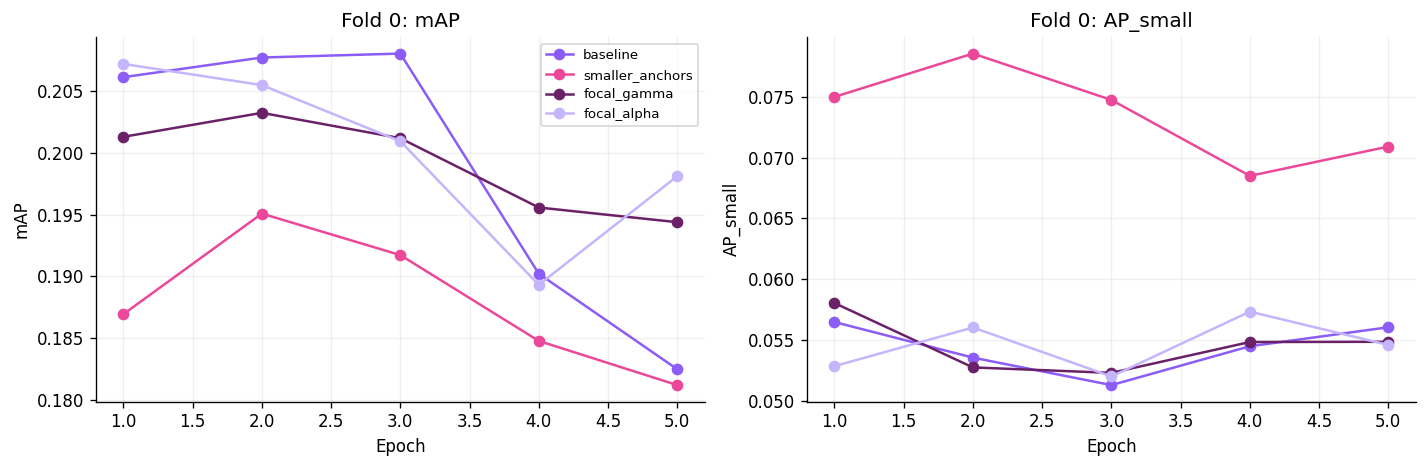

In [ ]:
import csv
import importlib.metadata as package_metadata
import shutil

FINAL_DIR = PROJECT_DIR / 'retinanet_final'
FINAL_DIR.mkdir(parents=True, exist_ok=True)
CHUNK_FRAMES = 100
MAX_DETECTIONS = 500
EVAL_MAX_DETS = 100  # Same protocol as the detector experiments.
RUN_POOLED_OOF = False
BENCHMARK_IMAGES = 64
FASTER_RCNN_BENCHMARK = PROJECT_DIR / 'faster_rcnn_val_benchmark.csv'

# Completed runs are inspected; nothing in this section starts training.
search_table = pd.read_csv(RUNS_DIR / 'retinanet_search.csv')
cv_table = pd.read_csv(RUNS_DIR / 'retinanet_cv.csv')
selected_configuration = json.loads((RUNS_DIR / 'retinanet_selected.json').read_text())
selected_config_id = hashlib.sha256(
    json.dumps(selected_configuration, sort_keys=True).encode()
).hexdigest()[:12]
MODEL_PATHS = {
    f'fold{fold}': RUNS_DIR / f'retinanet_{selected_config_id}_fold{fold}' / 'best.pt'
    for fold in range(3)
}
assert all(path.is_file() for path in MODEL_PATHS.values()), MODEL_PATHS
print('Selected configuration:', selected_config_id)
print('Free space at output mount (GiB; Drive quota can differ):',
      round(shutil.disk_usage(FINAL_DIR).free / 2**30, 2))
display(search_table[['stage', 'accepted', 'mAP', 'AP50', 'AP_small']])
display(cv_table.drop_duplicates(['configuration', 'fold']))
cv_summary = cv_table.groupby('configuration')[['mAP', 'AP50', 'AP_small']].agg(['mean', 'std'])
display(cv_summary)
cv_summary.to_csv(FINAL_DIR / 'cv_summary.csv')

# Plot observed histories, including unsuccessful experiments.
import matplotlib.pyplot as plt
PURPLE, PINK, LAVENDER, PLUM = '#8B5CF6', '#EC4899', '#C4B5FD', '#6B2167'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.18, 'figure.dpi': 120})
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for color, (_, row) in zip([PURPLE, PINK, PLUM, LAVENDER], search_table.iterrows()):
    history_path = Path(row['run_dir']) / 'history.csv'
    assert history_path.is_file(), history_path
    history = pd.read_csv(history_path)
    for ax, metric in zip(axes, ['mAP', 'AP_small']):
        ax.plot(history['epoch'], history[metric], 'o-', color=color, label=row['stage'])
        ax.set(xlabel='Epoch', ylabel=metric, title=f'Fold 0: {metric}')
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FINAL_DIR / 'search_curves.png', bbox_inches='tight')
plt.show()

_atomic_json(FINAL_DIR / 'environment.json', {
    'python': platform.python_version(), 'torch': torch.__version__,
    'torchvision': torchvision.__version__, 'gpu': torch.cuda.get_device_name(DEVICE),
    'packages': {name: package_metadata.version(name) for name in
                 ['numpy', 'pandas', 'pycocotools', 'ensemble-boxes']},
    'evaluation_max_dets': EVAL_MAX_DETS, 'submission_max_dets': MAX_DETECTIONS,
})

### 2. Three fold models on the same official validation set

We infer with each fold's best checkpoint. The official validation sequences do not overlap the training videos, so every model is evaluated on the same previously untrained scenes. We load one model at a time and save predictions in chunks of 100 images. The cache identity includes the checkpoint checksum, the image manifest and the inference environment.

We keep scores and original pixel coordinates rather than rendering or retaining image tensors in RAM.

In [ ]:
with (DATA_ROOT / 'val/annotations_coco.json').open() as file:
    official_val_coco = json.load(file)
val_table = pd.DataFrame(official_val_coco['images']).rename(columns={'id': 'image_id'})
val_table = val_table.sort_values('image_id').reset_index(drop=True)
assert len(val_table) == 2846 and val_table['image_id'].is_unique
assert set(train_frames['video']).isdisjoint(val_table['video'])
val_gt = build_eval_coco(official_val_coco, val_table['image_id'])

test_table = pd.read_csv(DATA_ROOT / 'test_images.csv')
assert len(test_table) == 3811 and test_table['image_id'].is_unique
# Keep the real competition IDs separately; cached IDs must be integers.
test_manifest = test_table.rename(columns={'image_id': 'submission_id'}).copy()
test_manifest['image_id'] = np.arange(1, len(test_manifest) + 1)

class InferenceDataset(Dataset):
    def __init__(self, frames, image_root):
        self.frames = frames.reset_index(drop=True).copy()
        self.image_root = Path(image_root)
    def __len__(self):
        return len(self.frames)
    def __getitem__(self, index):
        row = self.frames.iloc[index]
        with Image.open(self.image_root / row['file_name']) as source:
            image = source.convert('RGB')
            assert image.size == (int(row['width']), int(row['height']))
            tensor = pil_to_tensor(image).float() / 255.0
        return tensor, {'image_id': torch.tensor(int(row['image_id']), dtype=torch.int64)}


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as file:
        for block in iter(lambda: file.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def frame_digest(table):
    return hashlib.sha256(table.to_csv(index=False).encode()).hexdigest()


def cache_parts(cache):
    # Validate complete sequential coverage, including images with no predictions.
    manifest_path = cache.directory / 'manifest.json'
    manifest = json.loads(manifest_path.read_text())
    ids = manifest['image_ids']
    step = manifest['chunk_frames']
    paths = cache.chunks()
    assert len(paths) == math.ceil(len(ids) / step), cache.directory
    for number, path in enumerate(paths):
        with np.load(path, allow_pickle=False) as part:
            image_ids, rows = part['image_ids'], part['rows']
            assert image_ids.tolist() == ids[number * step:(number + 1) * step]
            assert rows.ndim == 2 and rows.shape[1] == 7
            assert np.isfinite(rows).all()
            assert set(rows[:, 0].astype(int)).issubset(set(image_ids.astype(int)))
            yield image_ids.copy(), rows.copy()


def cache_signature(cache):
    # Identity includes checkpoint SHA256, image manifest and inference settings.
    return hashlib.sha256((cache.directory / 'manifest.json').read_bytes()).hexdigest()


def run_inference_cached(name, checkpoint_path, dataset, split_name, cache_override=None):
    digest = file_sha256(checkpoint_path)
    identity = {'checkpoint_sha256': digest, 'dataset_sha256': frame_digest(dataset.frames),
                'split': split_name, 'precision': 'float32', 'preprocessing': 'checkpoint_config'}
    directory = Path(cache_override) if cache_override is not None else FINAL_DIR / 'predictions' / split_name / f'{name}_{digest[:12]}'
    manifest_path = directory / 'manifest.json'
    if manifest_path.is_file():
        saved_manifest = json.loads(manifest_path.read_text())
        assert saved_manifest['identity'] == identity, 'Prediction cache identity mismatch.'
        assert saved_manifest['image_ids'] == dataset.frames['image_id'].astype(int).tolist()
        assert saved_manifest['torch'] == str(torch.__version__)
        assert saved_manifest['torchvision'] == str(torchvision.__version__)
        assert saved_manifest['chunk_frames'] == CHUNK_FRAMES
        cache = PredictionCache(directory)
        try:
            for _ in cache_parts(cache):
                pass
        except AssertionError:
            pass  # A partial prefix is resumed and validated by predict_coco below.
        else:
            print(f'{split_name}: {name}: using complete prediction cache.')
            return cache
    # predict_coco performs complete cache coverage/identity validation itself.
    checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
    model_config = checkpoint['identity']['model']
    model = build_retinanet(model_config, pretrained=False).to(DEVICE)
    model.load_state_dict(checkpoint['model'])
    del checkpoint
    gc.collect()
    loader = DataLoader(dataset, batch_size=2, shuffle=False, num_workers=0,
                        pin_memory=True, collate_fn=detection_collate)
    try:
        cache = predict_coco(model, loader, DEVICE,
                             description=f'{split_name}: {name}', cache_dir=directory,
                             cache_identity=identity, chunk_frames=CHUNK_FRAMES)
    finally:
        del model, loader
        gc.collect()
        torch.cuda.empty_cache()
    # Read only a chunk at a time while verifying IDs.
    for _ in cache_parts(cache):
        pass
    return cache

val_dataset = InferenceDataset(val_table, DATA_ROOT / 'val')
VAL_CACHES = {}
for name, checkpoint_path in MODEL_PATHS.items():
    VAL_CACHES[name] = run_inference_cached(name, checkpoint_path, val_dataset, 'official_val')
print('All three models have predictions on the SAME official validation sequences.')

official_val: fold0: resuming inference at frame 0/2846.


official_val: fold0:   0%|          | 0/2846 [00:00<?, ?it/s]

official_val: fold1: resuming inference at frame 0/2846.


official_val: fold1:   0%|          | 0/2846 [00:00<?, ?it/s]

official_val: fold2: resuming inference at frame 0/2846.


official_val: fold2:   0%|          | 0/2846 [00:00<?, ?it/s]

All three models have predictions on the SAME official validation sequences.


### 3. Declared fusion search and sanity checks

We compare three single models, class-aware NMS at IoU 0.50, and equal-weight WBF at IoU {0.50, 0.65} with pre-fusion score cutoffs {0.001, 0.01}. These eight candidates reuse the same model predictions. We cap every candidate at 500 detections per image.

WBF combines coordinates of overlapping boxes within the same class using confidence-based weights; it can improve agreement but may merge nearby objects in dense scenes. We use the authors' implementation, with normalized corner coordinates at its interface and pixel `xywh` in our caches: [Weighted Boxes Fusion code](https://github.com/ZFTurbo/Weighted-Boxes-Fusion), [paper](https://arxiv.org/abs/1910.13302). This is an inference experiment, separate from the required anchor/loss training experiments.

In [ ]:
from ensemble_boxes import weighted_boxes_fusion


def empty_rows():
    return np.empty((0, 7), dtype=np.float64)


def top_detections(rows, limit=MAX_DETECTIONS):
    if not len(rows):
        return empty_rows()
    return rows[np.argsort(-rows[:, 2], kind='stable')[:limit]]


def numpy_class_nms(rows, iou_threshold):
    kept = []
    for category_id in np.unique(rows[:, 1]):
        candidates = rows[rows[:, 1] == category_id]
        boxes = candidates[:, 3:7].copy()
        boxes[:, 2:] += boxes[:, :2]
        areas = candidates[:, 5] * candidates[:, 6]
        order = np.argsort(-candidates[:, 2], kind='stable')
        while len(order):
            index = order[0]
            kept.append(candidates[index])
            others = order[1:]
            lo = np.maximum(boxes[index, :2], boxes[others, :2])
            hi = np.minimum(boxes[index, 2:], boxes[others, 2:])
            intersection = np.maximum(hi - lo, 0).prod(axis=1)
            union = areas[index] + areas[others] - intersection
            overlaps = np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)
            order = others[overlaps <= iou_threshold]
    return top_detections(np.asarray(kept).reshape(-1, 7))


def fuse_one_image(model_rows, width, height, settings):
    if settings['method'] == 'single':
        return top_detections(model_rows[0])
    if settings['method'] == 'nms':
        combined = np.concatenate(model_rows) if model_rows else empty_rows()
        return numpy_class_nms(combined, settings['iou'])
    if settings['method'] != 'wbf':
        raise ValueError(settings['method'])
    boxes_list, scores_list, labels_list = [], [], []
    scale = np.array([width, height, width, height], dtype=np.float64)
    for rows in model_rows:
        boxes = rows[:, 3:7].copy()
        boxes[:, 2:] += boxes[:, :2]
        boxes = np.clip(boxes / scale, 0, 1)
        boxes_list.append(boxes.tolist())
        scores_list.append(rows[:, 2].tolist())
        labels_list.append(rows[:, 1].astype(int).tolist())
    boxes, scores, labels = weighted_boxes_fusion(
        boxes_list, scores_list, labels_list,
        weights=[1.0] * len(model_rows),
        iou_thr=settings['iou'], skip_box_thr=settings['skip'], conf_type='avg',
    )
    if not len(boxes):
        return empty_rows()
    boxes = np.asarray(boxes, dtype=np.float64).reshape(-1, 4) * scale
    boxes[:, 2:] -= boxes[:, :2]
    image_id = next(int(rows[0, 0]) for rows in model_rows if len(rows))
    rows = np.column_stack([np.full(len(scores), image_id), labels, scores, boxes])
    valid = np.isfinite(rows).all(axis=1) & (rows[:, 5:7] > 0).all(axis=1)
    return top_detections(rows[valid])


def fusion_cache(frame_table, source_caches, settings, split_name):
    names = settings['members']
    sources = [source_caches[name] for name in names]
    identity = {'format': 'fusion-v1', 'settings': settings,
                'sources': [cache_signature(cache) for cache in sources],
                'table': frame_digest(frame_table),
                'ensemble_boxes': package_metadata.version('ensemble-boxes')}
    key = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:16]
    directory = FINAL_DIR / 'fusion' / split_name / key
    directory.mkdir(parents=True, exist_ok=True)
    manifest_path = directory / 'manifest.json'
    manifests = [json.loads((source.directory / 'manifest.json').read_text()) for source in sources]
    ids = frame_table['image_id'].astype(int).tolist()
    assert all(m['image_ids'] == ids for m in manifests)
    assert all(m['chunk_frames'] == CHUNK_FRAMES for m in manifests)
    manifest = {'format': 1, 'identity': identity, 'image_ids': ids, 'chunk_frames': CHUNK_FRAMES}
    if manifest_path.exists():
        assert json.loads(manifest_path.read_text()) == manifest
    else:
        assert not list(directory.glob('part_*.npz'))
        _atomic_json(manifest_path, manifest)
    indexed_frames = frame_table.set_index('image_id')
    for number, start in enumerate(tqdm(range(0, len(ids), CHUNK_FRAMES), desc=f"Fusion {settings['name']}", leave=False)):
        part_path = directory / f'part_{number:06d}.npz'
        expected_ids = ids[start:start + CHUNK_FRAMES]
        if part_path.is_file():
            with np.load(part_path, allow_pickle=False) as saved:
                assert saved['image_ids'].tolist() == expected_ids
                assert np.isfinite(saved['rows']).all()
            continue
        parts = []
        for source in sources:
            with np.load(source.directory / part_path.name, allow_pickle=False) as part:
                assert part['image_ids'].tolist() == expected_ids
                parts.append(part['rows'].copy())
        fused_rows = []
        for image_id in expected_ids:
            image = indexed_frames.loc[image_id]
            rows = [part[part[:, 0] == image_id] for part in parts]
            fused_rows.append(fuse_one_image(rows, int(image['width']), int(image['height']), settings))
        rows = np.concatenate(fused_rows) if fused_rows else empty_rows()
        temporary = part_path.with_suffix('.npz.tmp')
        with temporary.open('wb') as file:
            np.savez(file, image_ids=np.asarray(expected_ids, dtype=np.int64), rows=rows)
            file.flush()
            os.fsync(file.fileno())
        os.replace(temporary, part_path)
        del parts, fused_rows, rows
    cache = PredictionCache(directory)
    for _ in cache_parts(cache):
        pass
    return cache

# A small, declared validation search. Equal model weights avoid fitting extra weights.
CANDIDATES = [
    {'name': name, 'method': 'single', 'members': [name]}
    for name in MODEL_PATHS
] + [
    {'name': 'nms_050', 'method': 'nms', 'members': list(MODEL_PATHS), 'iou': 0.50},
] + [
    {'name': f'wbf_{int(iou * 100):03d}_skip{skip:g}', 'method': 'wbf',
     'members': list(MODEL_PATHS), 'iou': iou, 'skip': skip}
    for iou in [0.50, 0.65] for skip in [0.001, 0.01]
]

# Lightweight deterministic checks; no model or GPU is needed.
a = np.array([[1, 1, .9, 10, 10, 20, 20]], dtype=np.float64)
b = np.array([[1, 1, .8, 12, 10, 20, 20]], dtype=np.float64)
example = {'method': 'wbf', 'iou': .5, 'skip': .001}
fused = fuse_one_image([a, b, empty_rows()], 100, 100, example)
assert len(fused) == 1 and 10 <= fused[0, 3] <= 12
assert fused[0, 1] == 1 and 0 < fused[0, 2] <= 1
assert not len(fuse_one_image([empty_rows()] * 3, 100, 100, example))
other_class = b.copy(); other_class[:, 1] = 2
assert len(fuse_one_image([a, other_class], 100, 100, example)) == 2
assert len(numpy_class_nms(np.concatenate([a, b, other_class]), .5)) == 2
print('Fusion checks passed: overlap, empty predictions, and class separation.')
display(pd.DataFrame(CANDIDATES))

Fusion checks passed: overlap, empty predictions, and class separation.


,name,method,members,iou,skip
0,fold0,single,[fold0],NaN,NaN
1,fold1,single,[fold1],NaN,NaN
2,fold2,single,[fold2],NaN,NaN
3,nms_050,nms,"[fold0, fold1, fold2]",0.50,NaN
4,wbf_050_skip0.001,wbf,"[fold0, fold1, fold2]",0.50,0.001
5,wbf_050_skip0.01,wbf,"[fold0, fold1, fold2]",0.50,0.010
6,wbf_065_skip0.001,wbf,"[fold0, fold1, fold2]",0.65,0.001
7,wbf_065_skip0.01,wbf,"[fold0, fold1, fold2]",0.65,0.010


### 4. Validation comparison and fixed selection

We select the highest COCO-style mAP at `maxDets=100`, keeping the detector-comparison protocol unchanged. We also report AP50, AP75, AP_small, AP_medium and AP_large. A single model wins an exact tie before an ensemble. We persist the selected settings before touching test predictions.

We also inspect results per validation video. Because these data select fusion settings, their metrics are validation results rather than an unbiased estimate of the selected pipeline's future performance. Our class-metric cache is scoped to the evaluated image subset to prevent accidentally reusing whole-split metrics for one video.

COCO class person: 253,741 predictions
COCO class bicycle: 101,026 predictions
COCO class car: 234,513 predictions
COCO class van: 118,005 predictions
COCO class truck: 131,750 predictions
COCO class tricycle: 101,581 predictions
COCO class bus: 103,877 predictions
COCO class motor: 160,008 predictions
COCO evaluation finished in 7.40 min.
COCO class person: 243,823 predictions
COCO class bicycle: 57,678 predictions
COCO class car: 254,571 predictions
COCO class van: 67,273 predictions
COCO class truck: 153,549 predictions
COCO class tricycle: 79,313 predictions
COCO class bus: 35,362 predictions
COCO class motor: 159,178 predictions
COCO evaluation finished in 6.74 min.
COCO class person: 194,928 predictions
COCO class bicycle: 81,713 predictions
COCO class car: 279,947 predictions
COCO class van: 98,230 predictions
COCO class truck: 145,432 predictions
COCO class tricycle: 102,615 predictions
COCO class bus: 80,130 predictions
COCO class motor: 179,508 predictions
COCO evaluation fin

Fusion nms_050:   0%|          | 0/29 [00:00<?, ?it/s]

COCO class person: 246,170 predictions
COCO class bicycle: 61,120 predictions
COCO class car: 251,654 predictions
COCO class van: 97,746 predictions
COCO class truck: 129,611 predictions
COCO class tricycle: 87,502 predictions
COCO class bus: 37,463 predictions
COCO class motor: 162,250 predictions
COCO evaluation finished in 6.93 min.


Fusion wbf_050_skip0.001:   0%|          | 0/29 [00:00<?, ?it/s]

COCO class person: 239,661 predictions
COCO class bicycle: 67,889 predictions
COCO class car: 254,696 predictions
COCO class van: 100,405 predictions
COCO class truck: 131,404 predictions
COCO class tricycle: 89,473 predictions
COCO class bus: 49,486 predictions
COCO class motor: 173,600 predictions
COCO evaluation finished in 7.16 min.


Fusion wbf_050_skip0.01:   0%|          | 0/29 [00:00<?, ?it/s]

... (3 outputs left out)

Fusion wbf_065_skip0.01:   0%|          | 0/29 [00:00<?, ?it/s]

COCO class person: 237,518 predictions
COCO class bicycle: 62,079 predictions
COCO class car: 249,970 predictions
COCO class van: 97,099 predictions
COCO class truck: 123,581 predictions
COCO class tricycle: 85,672 predictions
COCO class bus: 39,358 predictions
COCO class motor: 171,417 predictions
COCO evaluation finished in 7.04 min.


,candidate,members,mAP,AP50,AP75,AP_small,AP_medium,AP_large,max_dets,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
7,wbf_065_skip0.01,"fold0,fold1,fold2",0.175837,0.333763,0.163789,0.073934,0.168740,0.316649,100,0.239821,0.128636,0.368219,0.203568,0.151856,0.174225,0.041290,0.099081
6,wbf_065_skip0.001,"fold0,fold1,fold2",0.175837,0.333763,0.163789,0.073934,0.168740,0.316649,100,0.239821,0.128636,0.368219,0.203568,0.151855,0.174225,0.041290,0.099081
4,wbf_050_skip0.001,"fold0,fold1,fold2",0.172195,0.331243,0.158180,0.073113,0.165190,0.314657,100,0.233890,0.125510,0.363196,0.201757,0.142494,0.169348,0.041547,0.099820
5,wbf_050_skip0.01,"fold0,fold1,fold2",0.172164,0.331200,0.158138,0.073113,0.165191,0.314619,100,0.233897,0.125510,0.363196,0.201757,0.142236,0.169353,0.041546,0.099820
3,nms_050,"fold0,fold1,fold2",0.161176,0.322208,0.140892,0.067050,0.159501,0.290959,100,0.221876,0.128930,0.340970,0.199220,0.119826,0.146179,0.048614,0.083794
1,fold1,fold1,0.153583,0.292590,0.140117,0.061994,0.138066,0.310067,100,0.213211,0.092892,0.344626,0.187421,0.160580,0.158134,0.001457,0.070340
0,fold0,fold0,0.151721,0.302022,0.135150,0.052879,0.158991,0.265586,100,0.214429,0.122793,0.328714,0.181427,0.085781,0.125409,0.089000,0.066218
2,fold2,fold2,0.147087,0.281724,0.135800,0.048290,0.132627,0.295151,100,0.188100,0.091464,0.332548,0.147035,0.160819,0.127710,0.047438,0.081581


Selected inference strategy: {'name': 'wbf_065_skip0.01', 'method': 'wbf', 'members': ['fold0', 'fold1', 'fold2'], 'iou': 0.65, 'skip': 0.01}


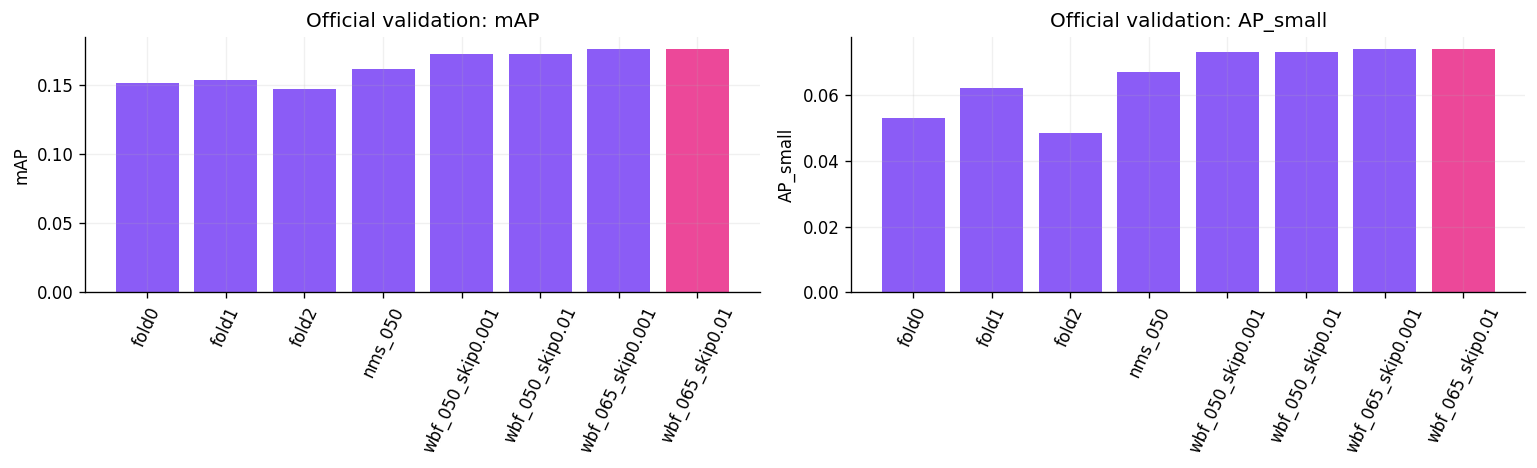

COCO class person: 46,400 predictions
COCO class bicycle: 11,535 predictions
COCO class car: 18,541 predictions
COCO class van: 5,852 predictions
COCO class truck: 8,783 predictions
COCO class tricycle: 6,207 predictions
COCO class bus: 6,089 predictions
COCO class motor: 24,029 predictions
COCO evaluation finished in 1.29 min.
COCO class person: 34,900 predictions
COCO class bicycle: 3,577 predictions
COCO class car: 28,838 predictions
COCO class van: 11,608 predictions
COCO class truck: 16,645 predictions
COCO class tricycle: 12,726 predictions
COCO class bus: 4,956 predictions
COCO class motor: 11,521 predictions
COCO evaluation finished in 1.67 min.
COCO class person: 23,300 predictions
COCO class bicycle: 9,623 predictions
COCO class car: 23,240 predictions
COCO class van: 4,971 predictions
COCO class truck: 4,081 predictions
COCO class tricycle: 6,220 predictions
COCO class bus: 2,536 predictions
COCO class motor: 20,739 predictions
COCO evaluation finished in 1.01 min.
COCO clas

,video,frames,mAP,AP50,AP75,AP_small,AP_medium,AP_large,max_dets
0,uav0000086_00000_v,464,0.145048,0.399175,0.066826,0.186375,0.163099,0.411207,100
1,uav0000117_02622_v,349,0.190964,0.373319,0.180668,0.022624,0.168806,0.284808,100
2,uav0000137_00458_v,233,0.247653,0.478471,0.215625,0.005690,0.184543,0.557127,100
3,uav0000182_00000_v,363,0.146437,0.309524,0.119976,0.095000,0.176329,0.392515,100
4,uav0000268_05773_v,978,0.117750,0.178346,0.127472,0.003045,0.081462,0.487852,100
5,uav0000305_00000_v,184,0.271929,0.375270,0.327309,0.025712,0.330519,0.297056,100
6,uav0000339_00001_v,275,0.255588,0.427519,0.264370,0.057970,0.276862,0.658247,100


In [ ]:
validation_records = []
CANDIDATE_CACHES = {}
for settings in CANDIDATES:
    if settings['method'] == 'single':
        cache = VAL_CACHES[settings['members'][0]]
    else:
        cache = fusion_cache(val_table, VAL_CACHES, settings, 'official_val')
    metrics, per_class = evaluate_coco_predictions(val_gt, cache, max_dets=EVAL_MAX_DETS)
    CANDIDATE_CACHES[settings['name']] = cache
    validation_records.append({
        'candidate': settings['name'], 'members': ','.join(settings['members']),
        **metrics, **{f'AP_{name}': value for name, value in per_class.items()},
    })
    pd.DataFrame(validation_records).to_csv(FINAL_DIR / 'official_val_candidates.csv', index=False)

validation_results = pd.DataFrame(validation_records)
assert validation_results['mAP'].notna().all()
# Stable sorting preserves the simpler single model when mAP is exactly tied.
winner_row = validation_results.sort_values('mAP', ascending=False, kind='stable').iloc[0]
WINNER_SETTINGS = next(c for c in CANDIDATES if c['name'] == winner_row['candidate'])
WINNER_CACHE = CANDIDATE_CACHES[WINNER_SETTINGS['name']]
selection = {
    'settings': WINNER_SETTINGS,
    'selection_split': 'official_val', 'selection_metric': 'mAP',
    'evaluation_max_dets': EVAL_MAX_DETS,
    'metrics': {name: float(winner_row[name]) for name in
                ['mAP', 'AP50', 'AP75', 'AP_small', 'AP_medium', 'AP_large']
                if np.isfinite(winner_row[name])},
    'checkpoint_sha256': {name: file_sha256(path) for name, path in MODEL_PATHS.items()},
    'validation_manifest': frame_digest(val_table),
}
_atomic_json(FINAL_DIR / 'selected_inference.json', selection)
display(validation_results.sort_values('mAP', ascending=False))
print('Selected inference strategy:', WINNER_SETTINGS)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ['mAP', 'AP_small']):
    colors = [PINK if name == WINNER_SETTINGS['name'] else PURPLE
              for name in validation_results['candidate']]
    ax.bar(validation_results['candidate'], validation_results[metric], color=colors)
    ax.set(ylabel=metric, title=f'Official validation: {metric}')
    ax.tick_params(axis='x', rotation=65)
fig.tight_layout()
fig.savefig(FINAL_DIR / 'inference_comparison.png', bbox_inches='tight')
plt.show()

# Per-sequence results expose scene variation rather than only the aggregate score.
sequence_records = []
for video, group in val_table.groupby('video', observed=True):
    metrics, _ = evaluate_coco_predictions(build_eval_coco(official_val_coco, group['image_id']),
                                         WINNER_CACHE, max_dets=EVAL_MAX_DETS,
                                         )
    sequence_records.append({'video': video, 'frames': len(group), **metrics})
sequence_results = pd.DataFrame(sequence_records)
sequence_results.to_csv(FINAL_DIR / 'official_val_by_sequence.csv', index=False)
display(sequence_results)

### 5. Measured inference speed and comparable benchmarks

We measure each detector at batch size 1, FP32, after five warm-up calls and with CUDA synchronization. Sampling spans the ordered validation set. The inference latency includes device transfers, resizing/normalization, the model and its built-in NMS, and transfer of outputs to CPU. End-to-end FPS additionally includes image loading. Cached prediction loading is not FPS.

These measurements describe the individual RetinaNet models, not the three-model ensemble. The full ensemble requires all member forwards plus fusion and is slower; we do not label single-model FPS as ensemble FPS.

The Faster R-CNN comparison remains open until its tuned model is evaluated on the same official validation split and timing protocol. A compatible CSV can be placed at `ucu_ai_hw2/faster_rcnn_val_benchmark.csv`; missing results are not filled with values from a different fold or device.

In [ ]:
# Time real inference; cached prediction retrieval is never reported as model FPS.
@torch.inference_mode()
def benchmark_checkpoint(path, dataset, image_count=64):
    digest = file_sha256(path)
    fingerprint = {'checkpoint_sha256': digest, 'dataset': frame_digest(dataset.frames),
                   'images': image_count, 'batch_size': 1, 'precision': 'float32',
                   'torch': str(torch.__version__), 'torchvision': str(torchvision.__version__),
                   'gpu': torch.cuda.get_device_name(DEVICE)}
    key = hashlib.sha256(json.dumps(fingerprint, sort_keys=True).encode()).hexdigest()[:16]
    output = FINAL_DIR / f'speed_{key}.json'
    if output.is_file():
        return json.loads(output.read_text())
    checkpoint = torch.load(path, map_location='cpu', weights_only=False)
    config = checkpoint['identity']['model']
    model = build_retinanet(config, pretrained=False).to(DEVICE).eval()
    model.load_state_dict(checkpoint['model'])
    del checkpoint
    indices = np.linspace(0, len(dataset) - 1, min(image_count, len(dataset)), dtype=int)
    latencies, end_to_end = [], []
    torch.cuda.reset_peak_memory_stats(DEVICE)
    try:
        for _ in range(5):
            image, _ = dataset[int(indices[0])]
            outputs = model([image.to(DEVICE)])
        torch.cuda.synchronize(DEVICE)
        for index in tqdm(indices, desc='Speed benchmark', leave=False):
            full_start = time.perf_counter()
            image, _ = dataset[int(index)]
            torch.cuda.synchronize(DEVICE)
            start = time.perf_counter()
            outputs = model([image.to(DEVICE, non_blocking=False)])
            # Include the CPU transfer needed for output serialization.
            _ = [{key: value.cpu() for key, value in out.items()} for out in outputs]
            torch.cuda.synchronize(DEVICE)
            latencies.append(time.perf_counter() - start)
            end_to_end.append(time.perf_counter() - full_start)
        result = {'protocol': fingerprint, 'fps': 1 / float(np.mean(latencies)),
                  'mean_ms': 1000 * float(np.mean(latencies)),
                  'p50_ms': 1000 * float(np.median(latencies)),
                  'p95_ms': 1000 * float(np.quantile(latencies, .95)),
                  'end_to_end_fps': 1 / float(np.mean(end_to_end)),
                  'peak_allocated_GiB': torch.cuda.max_memory_allocated(DEVICE) / 2**30,
                  'min_size': config['min_size'], 'max_size': config['max_size']}
        _atomic_json(output, result)
        return result
    finally:
        del model
        gc.collect()
        torch.cuda.empty_cache()

speed_records = []
for name, path in MODEL_PATHS.items():
    result = benchmark_checkpoint(path, val_dataset, BENCHMARK_IMAGES)
    speed_records.append({'candidate': name, **{k: v for k, v in result.items() if k != 'protocol'}})
speed_table = pd.DataFrame(speed_records)
speed_table.to_csv(FINAL_DIR / 'retinanet_speed.csv', index=False)
display(speed_table)

single_model_comparison = validation_results.loc[
    validation_results['candidate'].isin(MODEL_PATHS)
].merge(speed_table, on='candidate', validate='one_to_one')
single_model_comparison['split'] = 'official_val'
single_model_comparison['batch_size'] = 1
single_model_comparison['gpu'] = torch.cuda.get_device_name(DEVICE)
single_model_comparison['precision'] = 'float32'
single_model_comparison.to_csv(FINAL_DIR / 'retinanet_val_benchmark.csv', index=False)

# Import only measurements made with this SAME validation/evaluation/speed protocol.
if FASTER_RCNN_BENCHMARK.is_file():
    faster = pd.read_csv(FASTER_RCNN_BENCHMARK)
    required = {'candidate', 'mAP', 'AP50', 'AP_small', 'fps',
                'split', 'max_dets', 'batch_size', 'gpu', 'precision',
                'AP_medium', 'AP_large', 'min_size', 'max_size'}
    assert required.issubset(faster.columns), required - set(faster.columns)
    assert faster['split'].eq('official_val').all()
    assert faster['max_dets'].eq(EVAL_MAX_DETS).all()
    assert faster['batch_size'].eq(1).all()
    assert faster['gpu'].eq(torch.cuda.get_device_name(DEVICE)).all()
    assert faster['precision'].eq('float32').all()
    assert faster['min_size'].eq(selected_configuration['model']['min_size']).all()
    assert faster['max_size'].eq(selected_configuration['model']['max_size']).all()
    display(pd.concat([faster, single_model_comparison], ignore_index=True))
else:
    print('OPEN REQUIREMENT: add Faster R-CNN results on the same official val split and timing protocol.')

Speed benchmark:   0%|          | 0/64 [00:00<?, ?it/s]

Speed benchmark:   0%|          | 0/64 [00:00<?, ?it/s]

Speed benchmark:   0%|          | 0/64 [00:00<?, ?it/s]

,candidate,fps,mean_ms,p50_ms,p95_ms,end_to_end_fps,peak_allocated_GiB,min_size,max_size
0,fold0,7.265426,137.638181,134.429939,154.876738,4.063004,0.417156,640,1152
1,fold1,7.098665,140.871566,137.869339,159.715583,4.023834,0.417156,640,1152
2,fold2,7.106772,140.710855,139.249190,155.215786,3.997439,0.417156,640,1152


OPEN REQUIREMENT: add Faster R-CNN results on the same official val split and timing protocol.


### 6. Failure diagnostics for our review

We inspect three distinct validation frames emphasizing missed small objects, class confusion, and localization/duplicates. The visual diagnostic uses score >= 0.30 and IoU >= 0.50, preserves positive matches before crowd exclusion, and is not the COCO evaluator. A missed object at this display threshold can still contribute to AP at a lower score. We inspect the actual overlays before assigning a cause; diagnostic labels are hypotheses, not ground-truth error attribution.

Removing a proposal stage means RetinaNet classifies a dense set of anchors directly. Easy negatives, small-object feature resolution, anchor/object mismatch and nearby-object suppression are mechanisms to examine. Focal loss, anchor changes, higher resolution and carefully validated fusion are possible responses. We use our measured results and visible examples to decide which explanations are supported, and write our own conclusions in the report.

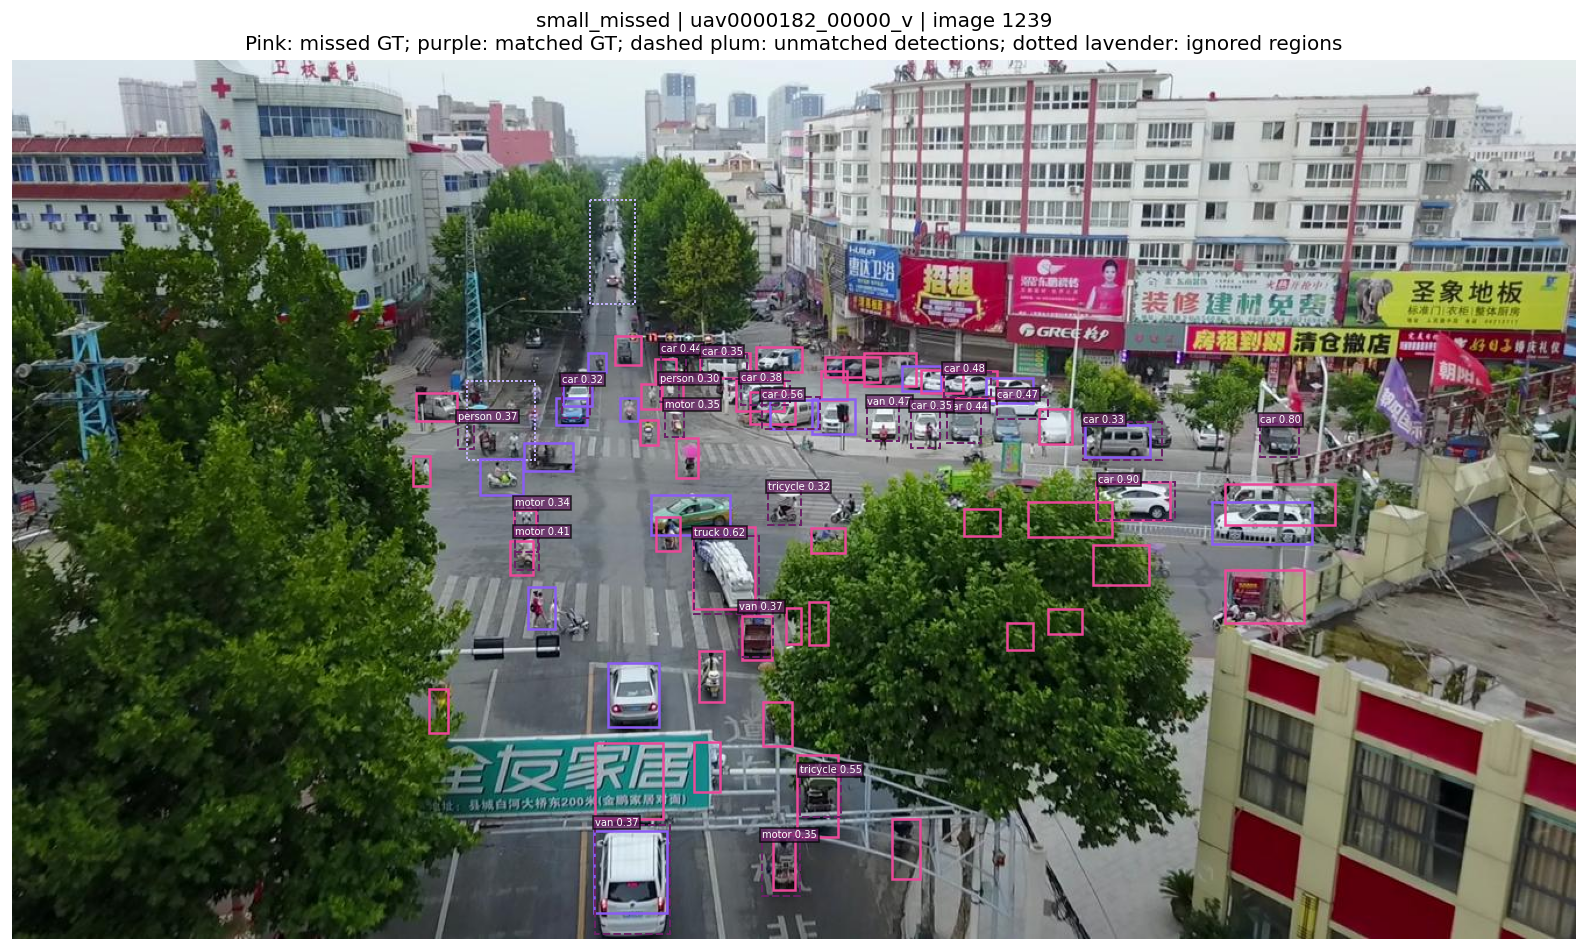

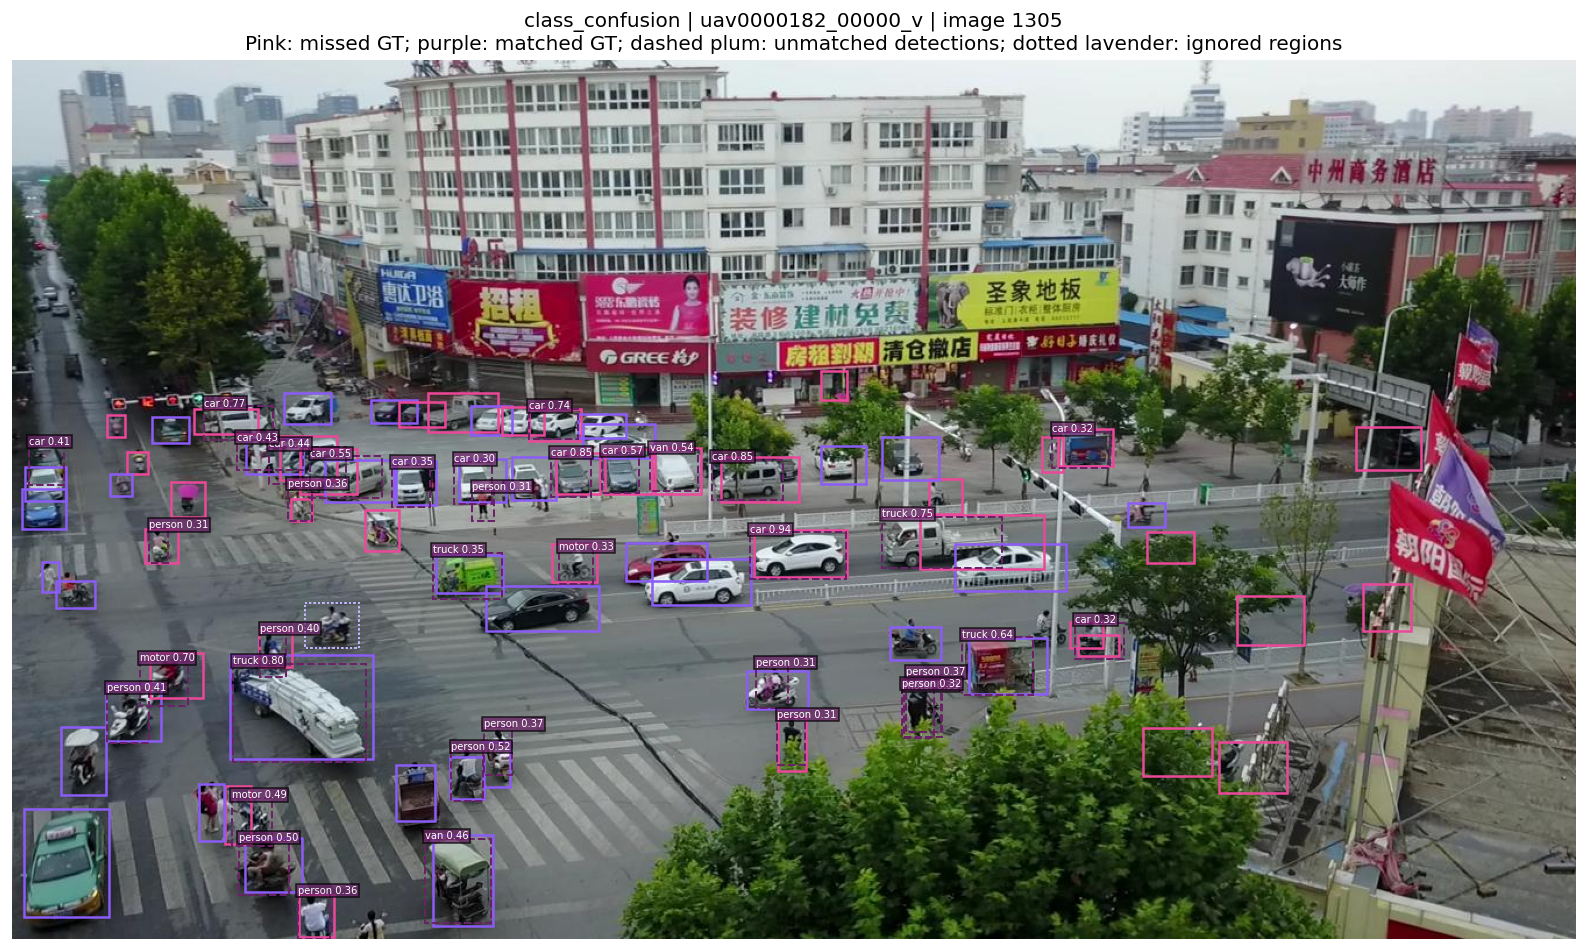

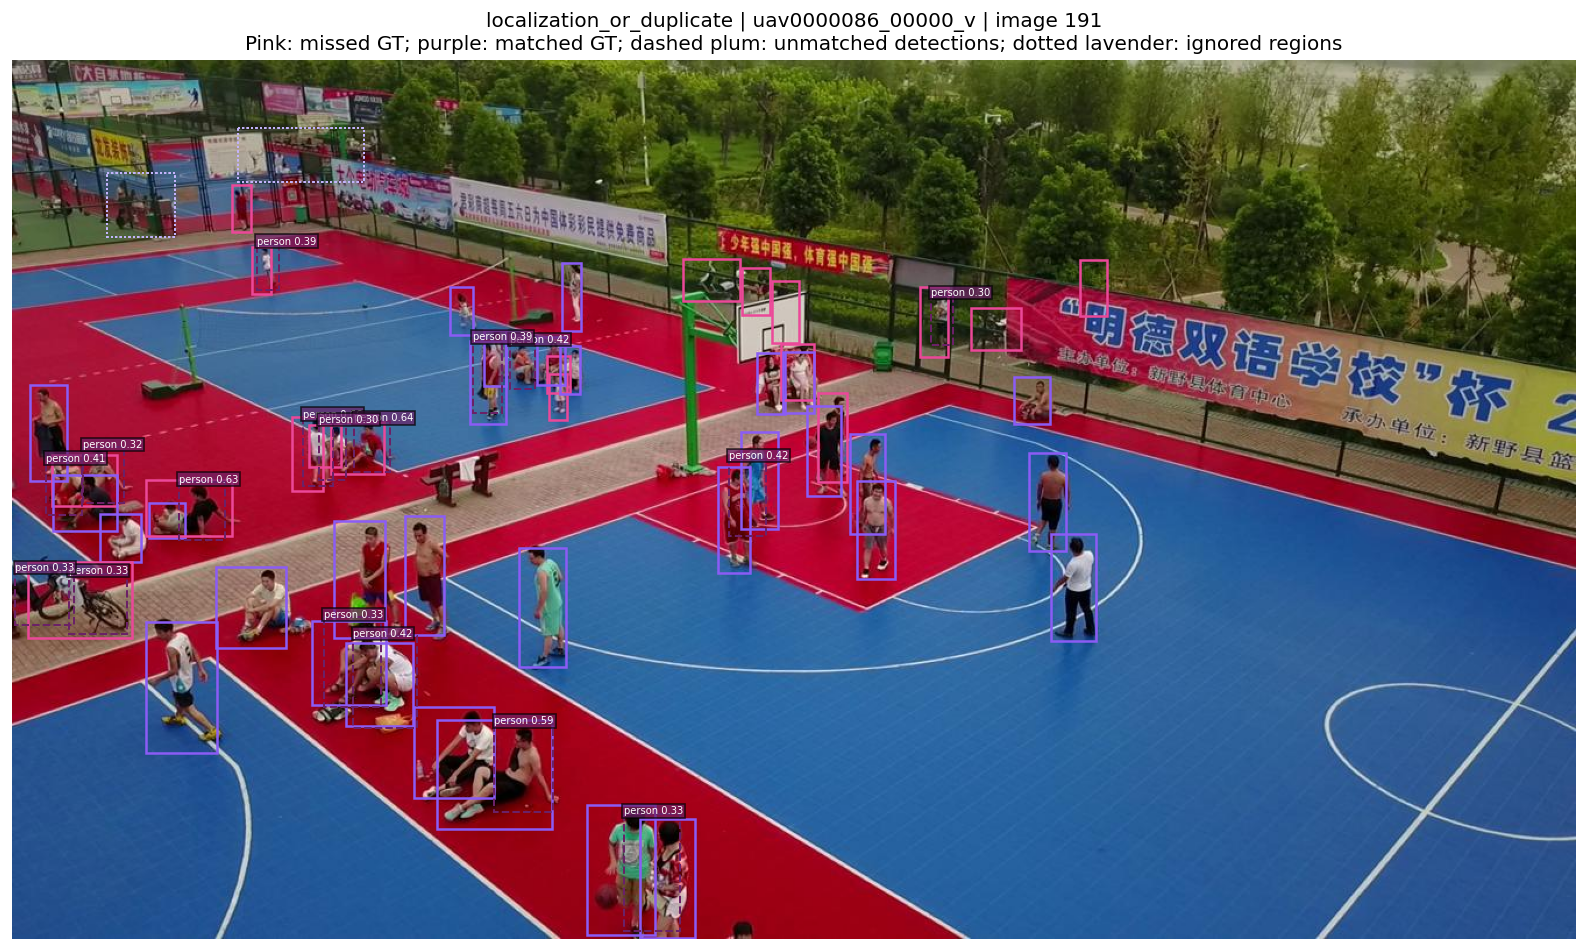

,focus,image_id,targets,missed,small_missed,true_positive,ignored,class_confusion,localization_or_duplicate,background_false_positive
0,small_missed,1239,59,43,30,16,0,11,6,7
1,class_confusion,1305,74,37,14,37,1,26,4,7
2,localization_or_duplicate,191,49,18,6,31,0,0,14,3


In [ ]:
# These are diagnostic threshold-based matches, not a replacement for COCO AP.
VIEW_SCORE = 0.30
VIEW_IOU = 0.50
val_annotations = defaultdict(list)
for annotation in official_val_coco['annotations']:
    val_annotations[int(annotation['image_id'])].append(annotation)


def xywh_iou(a, b):
    a, b = np.asarray(a).reshape(-1, 4), np.asarray(b).reshape(-1, 4)
    lo = np.maximum(a[:, None, :2], b[None, :, :2])
    hi = np.minimum(a[:, None, :2] + a[:, None, 2:], b[None, :, :2] + b[None, :, 2:])
    intersection = np.maximum(hi - lo, 0).prod(axis=2)
    union = a[:, 2:].prod(axis=1)[:, None] + b[:, 2:].prod(axis=1)[None, :] - intersection
    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def diagnostic_matches(image_id, rows):
    annotations = val_annotations[image_id]
    targets = [a for a in annotations if not (a.get('iscrowd', 0) or a.get('ignore', 0))]
    ignored = [a['bbox'] for a in annotations if a.get('iscrowd', 0) or a.get('ignore', 0)]
    boxes = np.asarray([a['bbox'] for a in targets], dtype=float).reshape(-1, 4)
    categories = np.asarray([a['category_id'] for a in targets])
    detections = top_detections(rows[rows[:, 2] >= VIEW_SCORE])
    ious = xywh_iou(detections[:, 3:], boxes)
    matched, statuses = set(), []
    for index, row in enumerate(detections):
        available = [j for j in range(len(boxes)) if j not in matched and categories[j] == row[1]]
        best = max(available, key=lambda j: ious[index, j]) if available else None
        if best is not None and ious[index, best] >= VIEW_IOU:
            matched.add(best); statuses.append('true_positive'); continue
        if ignored:
            crowd = np.asarray(ignored, dtype=float).reshape(-1, 4)
            lo = np.maximum(row[3:5], crowd[:, :2])
            hi = np.minimum(row[3:5] + row[5:7], crowd[:, :2] + crowd[:, 2:])
            ioa = np.maximum(hi - lo, 0).prod(axis=1) / (row[5] * row[6])
            if np.max(ioa) >= VIEW_IOU:
                statuses.append('ignored'); continue
        if len(boxes) and np.any((ious[index] >= VIEW_IOU) & (categories != row[1])):
            statuses.append('class_confusion')
        elif len(boxes) and np.any((ious[index] >= .1) & (categories == row[1])):
            statuses.append('localization_or_duplicate')
        else:
            statuses.append('background_false_positive')
    missed = [j for j in range(len(boxes)) if j not in matched]
    small_missed = sum(boxes[j, 2] * boxes[j, 3] < 32**2 for j in missed)
    record = {'image_id': image_id, 'targets': len(boxes), 'missed': len(missed),
              'small_missed': int(small_missed), **{name: statuses.count(name) for name in
              ['true_positive', 'ignored', 'class_confusion', 'localization_or_duplicate', 'background_false_positive']}}
    return record, boxes, missed, detections, statuses, ignored

error_records = []
for ids, rows in cache_parts(WINNER_CACHE):
    for image_id in ids:
        record, *_ = diagnostic_matches(int(image_id), rows[rows[:, 0] == image_id])
        error_records.append(record)
error_table = pd.DataFrame(error_records)
error_table.to_csv(FINAL_DIR / 'diagnostic_errors_per_frame.csv', index=False)
chosen, used = [], set()
for focus in ['small_missed', 'class_confusion', 'localization_or_duplicate']:
    available = error_table.loc[~error_table['image_id'].isin(used)]
    row = available.sort_values([focus, 'missed'], ascending=False, kind='stable').iloc[0]
    used.add(int(row['image_id']))
    chosen.append({'focus': focus, **row.to_dict()})
chosen_table = pd.DataFrame(chosen)
# The student fills these after inspecting the images; no automatic report conclusions.
chosen_table['our_observation'] = ''
chosen_table['plausible_cause_to_check'] = ''
chosen_table['possible_next_experiment'] = ''
chosen_table.to_csv(FINAL_DIR / 'failure_cases_to_review.csv', index=False)
selected_rows = {}
for ids, rows in cache_parts(WINNER_CACHE):
    for image_id in used & set(map(int, ids)):
        selected_rows[image_id] = rows[rows[:, 0] == image_id]

from matplotlib.patches import Rectangle
categories_by_id = {c['id']: c['name'] for c in official_val_coco['categories']}
for example in chosen:
    image_id = int(example['image_id'])
    frame = val_table.set_index('image_id').loc[image_id]
    _, boxes, missed, detections, statuses, ignored = diagnostic_matches(image_id, selected_rows[image_id])
    with Image.open(DATA_ROOT / 'val' / frame['file_name']) as image:
        fig, ax = plt.subplots(figsize=(14, 8))
        ax.imshow(image.convert('RGB'))
    for x, y, w, h in ignored:
        ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=LAVENDER, linestyle=':', linewidth=1))
    for j, (x, y, w, h) in enumerate(boxes):
        ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=PINK if j in missed else PURPLE, linewidth=1.5))
    for detection, status in zip(detections, statuses):
        if status in ['true_positive', 'ignored']:
            continue
        x, y, w, h = detection[3:]
        ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=PLUM, linestyle='--', linewidth=1.2))
        ax.text(x, y, f"{categories_by_id[int(detection[1])]} {detection[2]:.2f}", color='white',
                fontsize=6, bbox={'facecolor': PLUM, 'alpha': .7, 'pad': 1})
    ax.set_title(f"{example['focus']} | {frame['video']} | image {image_id}\nPink: missed GT; purple: matched GT; dashed plum: unmatched detections; dotted lavender: ignored regions")
    ax.axis('off')
    fig.tight_layout()
    fig.savefig(FINAL_DIR / f'failure_{image_id}.png', bbox_inches='tight')
    plt.show()
display(chosen_table.drop(columns=['our_observation', 'plausible_cause_to_check', 'possible_next_experiment']))

### 7. Test inference and validated submission

We apply exactly the validation-selected settings, with the same checkpoints and preprocessing, to the test frames. If an ensemble wins we use all three members; if a single model wins we use that model. No training or test-based tuning occurs here. We save partial test results on Drive, validate every serialized detection, and publish the CSV only after checking all 3,811 image IDs.

The submission uses **0-based class, score, top-left x, top-left y, width, height**, all boxes in original pixel coordinates. Empty predictions produce an empty field. We save checksums and checkpoint provenance alongside the CSV. Upload to Kaggle is a separate manual action.

In [ ]:
# Test is used only after the validation strategy has been selected and persisted.
TEST_CACHES = {}
test_dataset = InferenceDataset(test_manifest, DATA_ROOT)
for name in WINNER_SETTINGS['members']:
    TEST_CACHES[name] = run_inference_cached(name, MODEL_PATHS[name], test_dataset, 'test')
if WINNER_SETTINGS['method'] == 'single':
    FINAL_TEST_CACHE = TEST_CACHES[WINNER_SETTINGS['members'][0]]
else:
    FINAL_TEST_CACHE = fusion_cache(test_manifest, TEST_CACHES, WINNER_SETTINGS, 'test')


def write_submission_from_cache(frame_table, cache, destination):
    table = frame_table.set_index('image_id')
    seen = set()
    predictions = {}
    for ids, rows in cache_parts(cache):
        for image_id in ids:
            image_id = int(image_id)
            assert image_id in table.index and image_id not in seen
            seen.add(image_id)
            frame = table.loc[image_id]
            selected = top_detections(rows[rows[:, 0] == image_id])
            if len(selected):
                assert np.isfinite(selected).all()
                assert np.equal(selected[:, 1], np.floor(selected[:, 1])).all()
                assert ((selected[:, 1] >= 1) & (selected[:, 1] <= 8)).all()
                assert ((selected[:, 2] >= 0) & (selected[:, 2] <= 1)).all()
                assert (selected[:, 3:5] >= -1e-5).all()
                assert (selected[:, 5:7] > 0).all()
                assert (selected[:, 3] + selected[:, 5] <= float(frame['width']) + .001).all()
                assert (selected[:, 4] + selected[:, 6] <= float(frame['height']) + .001).all()
            groups = [f'{int(r[1]) - 1} ' + ' '.join(f'{float(v):.9g}' for v in r[2:]) for r in selected]
            predictions[image_id] = ' '.join(groups)
    assert seen == set(table.index)
    submission = pd.DataFrame({
        'image_id': frame_table['submission_id'].astype(str).tolist(),
        'PredictionString': [predictions[int(i)] for i in frame_table['image_id']],
    })
    assert submission['image_id'].is_unique
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix('.csv.tmp')
    submission.to_csv(temporary, index=False)
    # Read the actual bytes back before publishing the final CSV.
    reread = pd.read_csv(temporary, keep_default_na=False, dtype={'image_id': str})
    assert list(reread.columns) == ['image_id', 'PredictionString']
    assert reread['image_id'].tolist() == frame_table['submission_id'].astype(str).tolist()
    for index, value in enumerate(reread['PredictionString']):
        tokens = value.split()
        assert len(tokens) % 6 == 0 and len(tokens) // 6 <= MAX_DETECTIONS
        for offset in range(0, len(tokens), 6):
            category, score, x, y, w, h = map(float, tokens[offset:offset + 6])
            assert category.is_integer() and 0 <= category <= 7
            assert np.isfinite([score, x, y, w, h]).all()
            assert 0 <= score <= 1 and min(x, y) >= -1e-5 and min(w, h) > 0
            assert x + w <= float(frame_table.iloc[index]['width']) + .001
            assert y + h <= float(frame_table.iloc[index]['height']) + .001
    os.replace(temporary, destination)
    return submission

submission_path = FINAL_DIR / 'submission_retinanet_selected.csv'
submission = write_submission_from_cache(test_manifest, FINAL_TEST_CACHE, submission_path)
assert len(submission) == 3811
assert submission['image_id'].tolist() == test_table['image_id'].astype(str).tolist()
sample_path = DATA_ROOT / 'sample_submission.csv'
if sample_path.is_file():
    sample = pd.read_csv(sample_path, keep_default_na=False)
    assert set(sample['image_id']) == set(submission['image_id'])
_atomic_json(FINAL_DIR / 'submission_provenance.json', {
    **selection, 'test_manifest': frame_digest(test_manifest),
    'submission_file': submission_path.name, 'submission_sha256': file_sha256(submission_path),
    'image_count': len(submission), 'max_detections': MAX_DETECTIONS,
    'cache_signature': cache_signature(FINAL_TEST_CACHE),
})
print('READY:', submission_path)
print('Rows:', len(submission), '| Non-empty:', submission['PredictionString'].ne('').sum())
display(submission.head())
# Upload this CSV manually to Kaggle; this notebook does not submit it automatically.

test: fold0: resuming inference at frame 0/3811.


test: fold0:   0%|          | 0/3811 [00:00<?, ?it/s]

test: fold1: resuming inference at frame 0/3811.


test: fold1:   0%|          | 0/3811 [00:00<?, ?it/s]

test: fold2: resuming inference at frame 0/3811.


test: fold2:   0%|          | 0/3811 [00:00<?, ?it/s]

Fusion wbf_065_skip0.01:   0%|          | 0/39 [00:00<?, ?it/s]

READY: /content/drive/MyDrive/ucu_ai_hw2/retinanet_final/submission_retinanet_selected.csv
Rows: 3811 | Non-empty: 3811


,image_id,PredictionString
0,clip_001_0000001,0 0.882350683 780.240383 886.860673 63.5904694...
1,clip_001_0000002,0 0.884895325 776.974697 891.378372 64.1069412...
2,clip_001_0000003,0 0.861489654 972.361565 722.084033 36.8970108...
3,clip_001_0000004,0 0.873452365 758.902187 907.667127 67.2937202...
4,clip_001_0000005,0 0.895397663 1661.80595 804.605348 56.1372757...


### 8. Optional pooled out-of-fold evaluation

The default is `RUN_POOLED_OOF=False`: this optional summary is not needed to select inference or create the submission. With `RUN_POOLED_OOF=True` we also pool predictions from each model on its own held-out training videos, reusing complete best-epoch validation caches when available. Unavailable caches require inference, never retraining. This can be run after the submission is already saved; set the flag to False in the audit cell to defer it.

We never use the other two fold models to predict an OOF image: those models may have trained on it. Selecting a best epoch on each holdout makes these checkpoint-selection OOF estimates optimistic; this is not nested CV. The official-val fusion evaluation remains separate. We do not average per-fold AP and call it pooled AP.

In [ ]:
if RUN_POOLED_OOF:
    OOF_CACHES = {}
    all_holdout_ids = set()
    for name, path in MODEL_PATHS.items():
        fold_id = int(name.replace('fold', ''))
        holdout = train_frames.loc[train_frames['fold'].eq(fold_id)].copy()
        assert not (all_holdout_ids & set(holdout['image_id']))
        all_holdout_ids.update(map(int, holdout['image_id']))
        checkpoint = torch.load(path, map_location='cpu', weights_only=False)
        expected_identity = {'run': checkpoint['identity'], 'epoch': checkpoint['epoch'] - 1,
                             'global_step': checkpoint['global_step']}
        # Confirm this model never trained on the sequence being predicted.
        split = json.loads((path.parent / 'split.json').read_text())
        assert set(split['holdout']) == set(holdout['image_id'])
        assert set(split['fit']).isdisjoint(holdout['image_id'])
        best_epoch = int(checkpoint['epoch'])
        del checkpoint
        gc.collect()
        previous_cache = path.parent / f'validation_cache_epoch_{best_epoch:02d}'
        reusable = False
        if (previous_cache / 'manifest.json').is_file():
            manifest = json.loads((previous_cache / 'manifest.json').read_text())
            reusable = (manifest['identity'] == expected_identity and
                        manifest['image_ids'] == holdout['image_id'].astype(int).tolist() and
                        manifest['torch'] == str(torch.__version__) and
                        manifest['torchvision'] == str(torchvision.__version__))
            if reusable:
                try:
                    for _ in cache_parts(PredictionCache(previous_cache)):
                        pass
                except (AssertionError, OSError, ValueError):
                    reusable = False
        if reusable:
            OOF_CACHES[name] = PredictionCache(previous_cache)
            print(f'Using saved best-epoch OOF predictions: {name}')
        else:
            OOF_CACHES[name] = run_inference_cached(
                name, path, InferenceDataset(holdout, DATA_ROOT / 'train'), 'oof')
    assert all_holdout_ids == set(train_frames['image_id'])

    class CombinedOOFCache(PredictionCache):
        def __init__(self, caches):
            self.caches = caches
            signatures = {key: cache_signature(value) for key, value in caches.items()}
            digest = hashlib.sha256(json.dumps(signatures, sort_keys=True).encode()).hexdigest()[:16]
            self.directory = FINAL_DIR / 'pooled_oof' / digest
            self.directory.mkdir(parents=True, exist_ok=True)
            _atomic_json(self.directory / 'sources.json',
                         {key: cache_signature(value) for key, value in caches.items()})
        def rows_for_category(self, category_id):
            for cache in self.caches.values():
                yield from cache.rows_for_category(category_id)

    pooled_metrics, pooled_per_class = evaluate_coco_predictions(
        build_eval_coco(train_coco, train_frames['image_id']), CombinedOOFCache(OOF_CACHES),
        max_dets=EVAL_MAX_DETS)
    # Do not confuse pooled AP with the arithmetic mean of per-fold AP.
    _atomic_json(FINAL_DIR / 'pooled_oof_metrics.json', {
        'metrics': {k: float(v) for k, v in pooled_metrics.items() if np.isfinite(v)},
        'per_class': {k: float(v) for k, v in pooled_per_class.items() if np.isfinite(v)},
        'caveat': 'Best epochs were selected on their fold holdouts; these are checkpoint-selection OOF estimates, not nested unbiased CV.',
    })
    display(pd.DataFrame([pooled_metrics]))

### 9. Completion checklist

This table checks the available code and outputs. It cannot guarantee a grade. We still need to interpret our results, compare with the tuned Faster R-CNN under the same protocol, and write our own compact report. The rules explicitly permit AI-assisted code and prohibit AI-written reports. We do not generate `report.md` here.

The visualization bonus additionally requires feature/attention/Grad-CAM analysis and W&B logging. The training curves and diagnostic overlays here do not alone satisfy that bonus. We have not added temporal modeling or an architectural bonus experiment in this notebook.

In [ ]:
# A code/output checklist does not replace our own interpretation or report.
checks = [
    ('COCO-pretrained one-stage anchor-based detector', True, 'Existing training implementation and checkpoints'),
    ('Anchor-scale experiment', 'smaller_anchors' in set(search_table['stage']), 'See search curves and retinanet_search.csv'),
    ('Loss-parameter experiments', {'focal_gamma', 'focal_alpha'}.issubset(set(search_table['stage'])), 'Focal alpha/gamma change the classification loss'),
    ('Sequence CV: all three folds', set(cv_table.loc[cv_table['configuration'].eq('selected'), 'fold']) == {0, 1, 2}, 'See cv_summary.csv'),
    ('Same official validation split for all RetinaNet candidates', len(validation_results) == len(CANDIDATES), 'See official_val_candidates.csv'),
    ('Measured GPU inference speed', len(speed_table) == 3, 'Batch 1, FP32, warm-up, CUDA synchronization'),
    ('Three diagnostic failure examples', len(chosen_table) == 3, 'Inspect images and fill failure_cases_to_review.csv'),
    ('Validated submission CSV', submission_path.is_file(), '3811 unique image IDs, classes 0–7, pixel xywh, at most 500 detections'),
    ('Comparison with tuned Faster R-CNN', FASTER_RCNN_BENCHMARK.is_file(), 'Only comparable measurements can close this item'),
    ('Our explanation and conclusions', False, 'We write our own interpretation; the assignment prohibits AI-written reports'),
]
checklist = pd.DataFrame(checks, columns=['requirement', 'available', 'evidence_or_next_action'])
checklist.to_csv(FINAL_DIR / 'completion_checklist.csv', index=False)
display(checklist)
print('Submission:', submission_path)
print('Selected strategy:', WINNER_SETTINGS['name'])
print('No guarantee of leaderboard rank: selection uses our validation mAP, not test labels or public-LB tuning.')

,requirement,available,evidence_or_next_action
0,COCO-pretrained one-stage anchor-based detector,True,Existing training implementation and checkpoints
1,Anchor-scale experiment,True,See search curves and retinanet_search.csv
2,Loss-parameter experiments,True,Focal alpha/gamma change the classification loss
3,Sequence CV: all three folds,True,See cv_summary.csv
4,Same official validation split for all RetinaN...,True,See official_val_candidates.csv
5,Measured GPU inference speed,True,"Batch 1, FP32, warm-up, CUDA synchronization"
6,Three diagnostic failure examples,True,Inspect images and fill failure_cases_to_revie...
7,Validated submission CSV,True,"3811 unique image IDs, classes 0–7, pixel xywh..."
8,Comparison with tuned Faster R-CNN,False,Only comparable measurements can close this item
9,Our explanation and conclusions,False,We write our own interpretation; the assignmen...


Submission: /content/drive/MyDrive/ucu_ai_hw2/retinanet_final/submission_retinanet_selected.csv
Selected strategy: wbf_065_skip0.01
No guarantee of leaderboard rank: selection uses our validation mAP, not test labels or public-LB tuning.
